# v5 — Publication Diagnostics

Closes the three items blocking a draft:

1. **The `scpot2dens` rail** — identify the unphysical ~4×10³ cm⁻³ values and their cause.
2. **Model vs. analytic** — does the ML model beat `scpot2dens` on the same samples? This is
   the paper's core claim and has not yet been measured.
3. **Robustness** — multi-seed repeats, bootstrap confidence intervals, and fold-level spread,
   so every number reported has an uncertainty attached.

**Prerequisite:** run v4 Sections 0–1 first so `df`, `PHYS_FEATURES` exist. Cell 1 below
caches `df` to disk so later runs skip the download.

In [1]:
# ── Cache / restore / load the dataframe (self-contained) ────────────────────
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore')
CACHE = 'themis_v4_df.pkl'   # pickle: no pyarrow/fastparquet needed

def _build_df_from_scratch():
    """Runs the v4 loading pipeline. Only called if no df and no cache exist."""
    import pyspedas
    from pyspedas import get_data
    from pyspedas.projects.themis import scpot2dens, scpot2dens_nishimura

    DAYS   = ['2007-07-20', '2008-02-16', '2008-07-16', '2009-02-27']
    PROBES = ['a', 'b', 'c', 'd', 'e']
    RESAMPLE, RE_KM = '30s', 6371.0

    def safe_interp(t_src, y_src, t_ref):
        if t_src is None or y_src is None or len(np.atleast_1d(t_src)) == 0:
            return np.full(len(t_ref), np.nan)
        y = np.asarray(y_src, dtype=float); good = np.isfinite(y)
        if good.sum() < 2: return np.full(len(t_ref), np.nan)
        return np.interp(t_ref, np.asarray(t_src)[good], y[good],
                         left=np.nan, right=np.nan)

    OMNI_VARS = {'sw_bz':'BZ_GSM','sw_speed':'flow_speed','sw_dens':'proton_density',
                 'sw_pdyn':'Pressure','sym_h':'SYM_H'}
    frames = []
    for day in DAYS:
        TR = [f'{day}/00:00:00', f'{day}/23:59:59']
        print(f'\n==== {day} ====')
        try:
            pyspedas.projects.omni.data(trange=TR, datatype='1min', time_clip=True)
            omni = {k: get_data(v) for k, v in OMNI_VARS.items()}
        except Exception as e:
            print(f'  OMNI failed: {e}'); omni = {k: None for k in OMNI_VARS}

        for P in PROBES:
            try:
                pyspedas.projects.themis.esa(
                    trange=TR, probe=P, level='l2', time_clip=True,
                    varnames=[f'th{P}_peer_density', f'th{P}_peir_density',
                              f'th{P}_peer_sc_pot', f'th{P}_peer_avgtemp',
                              f'th{P}_peer_vthermal'])
                pyspedas.projects.themis.fgm(trange=TR, probe=P, level='l2', time_clip=True)
                pyspedas.projects.themis.state(trange=TR, probe=P, time_clip=True)

                ne_d = get_data(f'th{P}_peer_density')
                if ne_d is None:
                    print(f'  th{P}: no density'); continue
                t_ref = ne_d.times; ne = np.asarray(ne_d.y, dtype=float)

                def grab(nm):
                    d = get_data(nm)
                    return safe_interp(d.times, d.y, t_ref) if d is not None \
                           else np.full_like(ne, np.nan)

                scpot_i = grab(f'th{P}_peer_sc_pot')
                Te_i    = grab(f'th{P}_peer_avgtemp')
                vth_i   = grab(f'th{P}_peer_vthermal')
                ni_i    = grab(f'th{P}_peir_density')

                try:
                    b_d = get_data(f'th{P}_fgs_gsm')
                    B_i = safe_interp(b_d.times, np.linalg.norm(b_d.y, axis=1), t_ref)
                except Exception:
                    B_i = np.full_like(ne, np.nan)

                X_i = Y_i = Z_i = np.full_like(ne, np.nan); pos_d = None
                try:
                    pos_d = get_data(f'th{P}_pos_gsm')
                    if pos_d is not None and pos_d.y.ndim == 2:
                        X_i = safe_interp(pos_d.times, pos_d.y[:,0]/RE_KM, t_ref)
                        Y_i = safe_interp(pos_d.times, pos_d.y[:,1]/RE_KM, t_ref)
                        Z_i = safe_interp(pos_d.times, pos_d.y[:,2]/RE_KM, t_ref)
                except Exception:
                    pass
                R_i = np.sqrt(X_i**2 + Y_i**2 + Z_i**2)

                ne_sp = np.full_like(ne, np.nan)
                try:
                    dd = scpot2dens(scpot_i, t_ref, Te_i, t_ref, ne, t_ref,
                                    ni_i, t_ref, P)
                    if dd is not None: ne_sp = np.asarray(dd, dtype=float)
                except Exception as e:
                    print(f'  th{P} scpot2dens failed: {e}')

                ne_ni = np.full_like(ne, np.nan)
                try:
                    if pos_d is not None:
                        dn = scpot2dens_nishimura(scpot_i, t_ref, vth_i, t_ref,
                                                  ni_i, t_ref, pos_d.y, pos_d.times,
                                                  probe=P)
                        if dn is not None: ne_ni = np.asarray(dn, dtype=float)
                except Exception as e:
                    print(f'  th{P} nishimura failed: {e}')

                d = pd.DataFrame({'time':t_ref,'ne':ne,'ne_scpot':ne_sp,'ne_nish':ne_ni,
                                  'ni':ni_i,'scpot':scpot_i,'Te':Te_i,'vth':vth_i,
                                  'B':B_i,'x_re':X_i,'y_re':Y_i,'z_re':Z_i,'R_re':R_i})
                d['dt'] = pd.to_datetime(d['time'], unit='s')
                d = (d.set_index('dt').resample(RESAMPLE).median()
                      .dropna(subset=['ne']).reset_index())
                tt = d['dt'].astype('int64').values / 1e9
                for k, v in omni.items():
                    d[k] = safe_interp(v.times, v.y, tt) if v is not None else np.nan
                d['probe'], d['day'] = P, day
                d['ne_lag1'] = d['ne'].shift(1)
                d.dropna(subset=['ne','scpot','Te','B'], inplace=True)
                if len(d) >= 50:
                    frames.append(d.reset_index(drop=True)); print(f'  th{P}: {len(d)} pts')
            except Exception as e:
                print(f'  th{P} failed: {e}')

    out = pd.concat(frames, ignore_index=True)
    out = out[out['ne'] > 0].copy()
    out['log_ne'] = np.log10(out['ne'])
    return out.sort_values('dt').reset_index(drop=True)

if 'df' in globals():
    df.to_pickle(CACHE); print(f'Cached {len(df)} rows -> {CACHE}')
elif os.path.exists(CACHE):
    df = pd.read_pickle(CACHE); print(f'Restored {len(df)} rows from {CACHE}')
else:
    print('No df and no cache -- loading from scratch (this downloads data).')
    df = _build_df_from_scratch()
    df.to_pickle(CACHE)
    print(f'\nLoaded and cached {len(df)} rows -> {CACHE}')

if 'log_ne' not in df.columns:
    df = df[df['ne'] > 0].copy(); df['log_ne'] = np.log10(df['ne'])

PHYS_FEATURES = [c for c in ['scpot','Te','vth','B','R_re',
                             'sw_bz','sw_speed','sw_dens','sw_pdyn','sym_h']
                 if c in df.columns and df[c].notna().sum() > 500]
print('Rows:', len(df), '| Features:', PHYS_FEATURES)


Restored 47597 rows from themis_v4_df.pkl
Rows: 47597 | Features: ['scpot', 'Te', 'vth', 'B', 'R_re', 'sw_bz', 'sw_speed', 'sw_dens', 'sw_pdyn', 'sym_h']


---
## 1 — Diagnosing the `scpot2dens` rail

Three candidate explanations, tested in order:

- **Fill values** — a sentinel constant repeated exactly (the signature of a rail).
- **Saturation** — the analytic formula's exponential blowing up at low potential.
- **Sign/unit convention** — potential entering with the wrong sign, so the exponent
  flips and low-density points map to absurdly high densities.

In [2]:
# ── 1a. Is the rail a repeated constant? ──────────────────────────────────────
s = df['ne_scpot'].replace([np.inf, -np.inf], np.nan).dropna()
print(f'ne_scpot: {len(s)} finite values')
print(f'  range: {s.min():.4g} … {s.max():.4g}')
print(f'  >100 cm^-3 (unphysical here): {(s > 100).sum()} '
      f'({100*(s > 100).mean():.1f}%)\n')

top = s[s > 100].round(6).value_counts().head(10)
print('Most repeated high values (a single dominant value = fill/saturation constant):')
print(top.to_string())

# Exact-duplicate test: fill values repeat bit-for-bit, physical values do not
if len(top) and top.iloc[0] > 20:
    RAIL = float(top.index[0])
    print(f'\n→ Rail constant identified: {RAIL:.6g} cm^-3, repeated {top.iloc[0]} times')
else:
    RAIL = None
    print('\n→ No single repeated constant; rail is likely a saturating continuum.')

ne_scpot: 47597 finite values
  range: 0.0001032 … 2.29e+30
  >100 cm^-3 (unphysical here): 5846 (12.3%)

Most repeated high values (a single dominant value = fill/saturation constant):
ne_scpot
4665.179541    49
1715.105023    45
1826.320205    42
2152.256049    37
3048.975074    35
1569.360176    32
1777.677791    32
1793.725608    21
2296.669345    21
1893.560934    19

→ Rail constant identified: 4665.18 cm^-3, repeated 49 times


In [3]:
# ── 1b. What are the inputs doing where ne_scpot is unphysical? ───────────────
bad  = df['ne_scpot'] > 100
good = (df['ne_scpot'] > 0) & (df['ne_scpot'] <= 100)

cmp = pd.DataFrame({
    'unphysical (>100)': df.loc[bad,  ['scpot','Te','ne','B','R_re']].median(),
    'physical (<=100)' : df.loc[good, ['scpot','Te','ne','B','R_re']].median(),
}).round(3)
cmp['ratio'] = (cmp['unphysical (>100)'] / cmp['physical (<=100)']).round(3)
print('Median input values, unphysical vs physical output:\n')
print(cmp.to_string())

print(f'\nscpot sign check — negative values present: {(df["scpot"] < 0).sum()}')
print(f'scpot range: {df["scpot"].min():.3f} … {df["scpot"].max():.3f} V')
print('THEMIS sc_pot is stored POSITIVE for a positively-charged spacecraft.')
print('If the analytic formula expects the opposite sign, the exponent inverts —')
print('which maps genuinely LOW densities onto absurdly HIGH ones.')

Median input values, unphysical vs physical output:

       unphysical (>100)  physical (<=100)   ratio
scpot              1.643            11.068   0.148
Te               204.027           370.938   0.550
ne                 0.627             0.560   1.120
B                810.743            35.235  23.010
R_re               3.408            10.762   0.317

scpot sign check — negative values present: 9
scpot range: -17.963 … 92.429 V
THEMIS sc_pot is stored POSITIVE for a positively-charged spacecraft.
If the analytic formula expects the opposite sign, the exponent inverts —
which maps genuinely LOW densities onto absurdly HIGH ones.


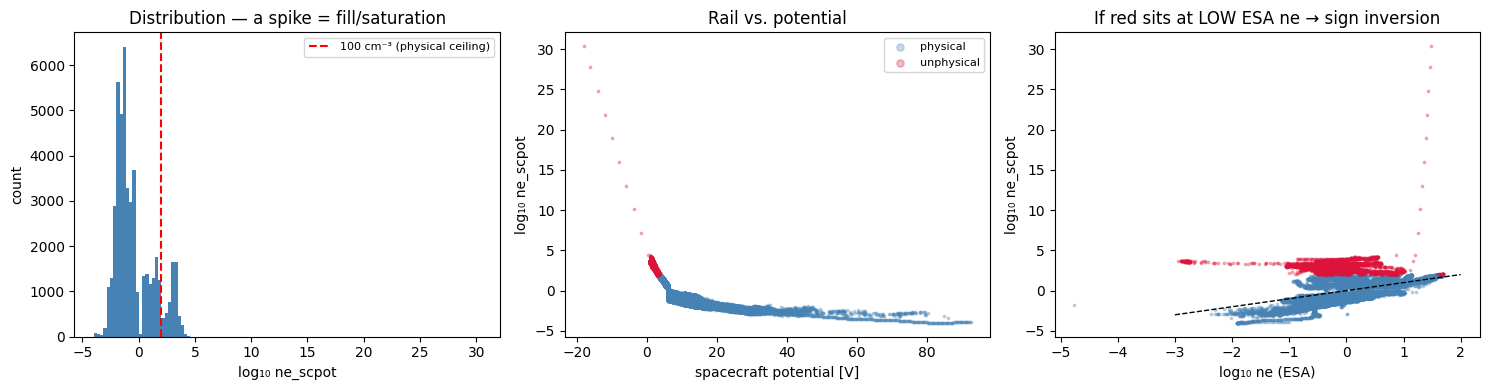

Read the right panel: if the unphysical points correspond to LOW true density,
the exponent is inverted (sign/unit bug). If they scatter at all densities,
they are fill values. If they cluster at one potential, it is saturation.


In [4]:
# ── 1c. Diagnostic plot: where does the rail live in input space? ─────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(np.log10(s.clip(lower=1e-4)), bins=120, color='steelblue')
axes[0].axvline(2, color='red', ls='--', label='100 cm⁻³ (physical ceiling)')
axes[0].set_xlabel('log₁₀ ne_scpot'); axes[0].set_ylabel('count')
axes[0].set_title('Distribution — a spike = fill/saturation')
axes[0].legend(fontsize=8)

axes[1].scatter(df.loc[good,'scpot'], np.log10(df.loc[good,'ne_scpot']),
                s=3, alpha=0.3, color='steelblue', label='physical')
axes[1].scatter(df.loc[bad,'scpot'], np.log10(df.loc[bad,'ne_scpot']),
                s=3, alpha=0.3, color='crimson', label='unphysical')
axes[1].set_xlabel('spacecraft potential [V]'); axes[1].set_ylabel('log₁₀ ne_scpot')
axes[1].set_title('Rail vs. potential'); axes[1].legend(fontsize=8, markerscale=3)

axes[2].scatter(np.log10(df.loc[good,'ne']), np.log10(df.loc[good,'ne_scpot']),
                s=3, alpha=0.3, color='steelblue')
axes[2].scatter(np.log10(df.loc[bad,'ne']), np.log10(df.loc[bad,'ne_scpot']),
                s=3, alpha=0.3, color='crimson')
lims = [-3, 2]
axes[2].plot(lims, lims, 'k--', lw=1)
axes[2].set_xlabel('log₁₀ ne (ESA)'); axes[2].set_ylabel('log₁₀ ne_scpot')
axes[2].set_title('If red sits at LOW ESA ne → sign inversion')
plt.tight_layout(); plt.show()

print('Read the right panel: if the unphysical points correspond to LOW true density,')
print('the exponent is inverted (sign/unit bug). If they scatter at all densities,')
print('they are fill values. If they cluster at one potential, it is saturation.')

In [5]:
# ── 1d. CORRECTED: input-domain mask + selection-bias audit ──────────────────
# Diagnosis: not fill values and not sign inversion. The analytic formula is an
# exponential in spacecraft potential that diverges as scpot -> 0. The affected
# samples are perigee passes (median R ~ 3.4 R_E, |B| ~ 810 nT ~ dipole at 3.4 R_E).
# Correct response: restrict to the formula's DOMAIN OF VALIDITY in scpot, and
# report what that restriction removes.

NE_CEIL = 100.0   # cm^-3, physical ceiling for these orbits

# Empirically locate the potential below which the estimate goes unphysical
grid = np.arange(0.5, 20.1, 0.5)
frac = [ (df.loc[df['scpot'] < t, 'ne_scpot'] > NE_CEIL).mean() for t in grid ]
ok   = [ (df.loc[df['scpot'] >= t, 'ne_scpot'] > NE_CEIL).mean() for t in grid ]
tbl = pd.DataFrame({'scpot_thresh': grid,
                    'frac_unphys_below': np.round(frac, 3),
                    'frac_unphys_above': np.round(ok, 4)})
# Smallest threshold that drives contamination above it under 1%
cand = tbl[tbl['frac_unphys_above'] < 0.01]
SCPOT_MIN = float(cand['scpot_thresh'].iloc[0]) if len(cand) else 5.0
print(tbl.to_string(index=False))
print(f'\n-> Validity threshold: scpot >= {SCPOT_MIN:.1f} V '
      f'(contamination above it: {float(cand["frac_unphys_above"].iloc[0])*100:.2f}%)'
      if len(cand) else f'\n-> Fallback threshold: {SCPOT_MIN} V')

# Apply the domain mask
valid_domain = (df['scpot'] >= SCPOT_MIN) & (df['ne_scpot'] > 1e-3) & (df['ne_scpot'] < NE_CEIL)
df['ne_scpot_clean'] = df['ne_scpot'].where(valid_domain)
n_tot = df['ne_scpot'].notna().sum()
n_kept = df['ne_scpot_clean'].notna().sum()
print(f'\nKept {n_kept} / {n_tot} ({100*n_kept/n_tot:.1f}%); '
      f'removed {n_tot-n_kept} ({100*(n_tot-n_kept)/n_tot:.1f}%)')

# ── Selection-bias audit: WHAT does the mask remove? ─────────────────────────
removed = df['ne_scpot'].notna() & df['ne_scpot_clean'].isna()
audit = pd.DataFrame({
    'removed': df.loc[removed, ['R_re','B','scpot','Te','ne']].median(),
    'kept'   : df.loc[df['ne_scpot_clean'].notna(), ['R_re','B','scpot','Te','ne']].median(),
}).round(3)
print('\nSelection-bias audit (median values):\n')
print(audit.to_string())
if 'day' in df.columns:
    print('\nRemoved fraction by day:')
    print((df[removed].groupby('day').size() /
           df[df['ne_scpot'].notna()].groupby('day').size()).round(3).to_string())
print('\nSTATE IN THE PAPER: the analytic estimate is only defined for scpot >= '
      f'{SCPOT_MIN:.1f} V, which excludes perigee passes below ~5 R_E. All')
print('model-vs-analytic comparisons are therefore restricted to the outer')
print('magnetosphere, and do not speak to inner-magnetosphere performance.')


 scpot_thresh  frac_unphys_below  frac_unphys_above
          0.5              1.000             0.1226
          1.0              1.000             0.1226
          1.5              1.000             0.0887
          2.0              1.000             0.0381
          2.5              1.000             0.0171
          3.0              1.000             0.0051
          3.5              0.892             0.0004
          4.0              0.685             0.0000
          4.5              0.605             0.0000
          5.0              0.536             0.0000
          5.5              0.471             0.0000
          6.0              0.417             0.0000
          6.5              0.377             0.0000
          7.0              0.349             0.0000
          7.5              0.322             0.0000
          8.0              0.297             0.0000
          8.5              0.278             0.0000
          9.0              0.263             0.0000
          9.

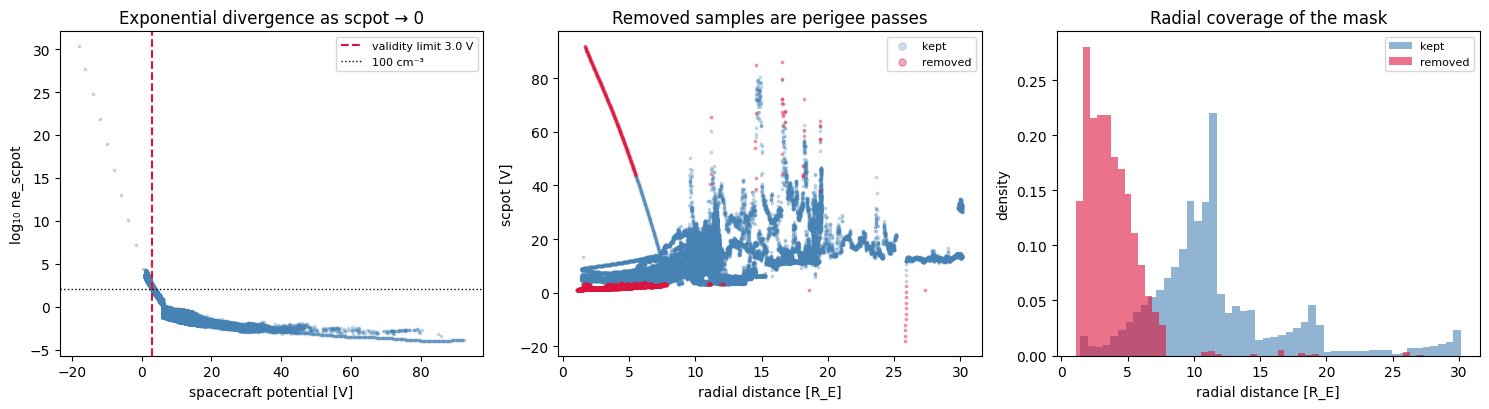

In [6]:
# ── 1e. Figure: the divergence and what the mask removes ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sub = df[df['ne_scpot'].notna()]
axes[0].scatter(sub['scpot'], np.log10(sub['ne_scpot'].clip(lower=1e-4)),
                s=3, alpha=0.25, color='steelblue')
axes[0].axvline(SCPOT_MIN, color='crimson', ls='--', lw=1.5,
                label=f'validity limit {SCPOT_MIN:.1f} V')
axes[0].axhline(np.log10(NE_CEIL), color='k', ls=':', lw=1, label='100 cm⁻³')
axes[0].set_xlabel('spacecraft potential [V]')
axes[0].set_ylabel('log₁₀ ne_scpot')
axes[0].set_title('Exponential divergence as scpot → 0')
axes[0].legend(fontsize=8)

axes[1].scatter(df.loc[~removed & df['ne_scpot'].notna(), 'R_re'],
                df.loc[~removed & df['ne_scpot'].notna(), 'scpot'],
                s=3, alpha=0.25, color='steelblue', label='kept')
axes[1].scatter(df.loc[removed, 'R_re'], df.loc[removed, 'scpot'],
                s=3, alpha=0.35, color='crimson', label='removed')
axes[1].set_xlabel('radial distance [R_E]'); axes[1].set_ylabel('scpot [V]')
axes[1].set_title('Removed samples are perigee passes')
axes[1].legend(fontsize=8, markerscale=3)

axes[2].hist(df.loc[~removed & df['ne_scpot'].notna(), 'R_re'].dropna(), bins=50,
             alpha=0.6, color='steelblue', label='kept', density=True)
axes[2].hist(df.loc[removed, 'R_re'].dropna(), bins=50,
             alpha=0.6, color='crimson', label='removed', density=True)
axes[2].set_xlabel('radial distance [R_E]'); axes[2].set_ylabel('density')
axes[2].set_title('Radial coverage of the mask')
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()


---
## 2 — Does the ML model beat the analytic formula?

The fair comparison uses **the same samples** for both: rows where the analytic estimate
is valid *and* the model has all its features. Three numbers matter:

- **Skill scores** (R², RMSE, MAE) for each, in log space.
- **A paired test** on the per-sample absolute errors — a Wilcoxon signed-rank, since
  error distributions are not normal.
- **A bootstrap CI on the difference**, which is what you actually report.

In [7]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import wilcoxon

def make_pipeline(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

BASE_MODEL = make_pipeline(RandomForestRegressor(
    n_estimators=200, random_state=42, n_jobs=-1))

work = df[df['ne'] > 0].copy()
work['log_ne'] = np.log10(work['ne'])
paired = work.dropna(subset=PHYS_FEATURES + ['log_ne', 'ne_scpot_clean']).copy()
paired['log_ne_analytic'] = np.log10(paired['ne_scpot_clean'])
print(f'Paired comparison set: {len(paired)} samples '
      f'({100*len(paired)/len(work):.1f}% of all rows)')

Xtr, Xte, ytr, yte, atr, ate = train_test_split(
    paired[PHYS_FEATURES].values, paired['log_ne'].values,
    paired['log_ne_analytic'].values, test_size=0.30, shuffle=False)

mdl = clone(BASE_MODEL); mdl.fit(Xtr, ytr)
pred_ml = mdl.predict(Xte)

rows = []
for name, pred in [('ML (Random Forest)', pred_ml), ('Analytic (scpot2dens)', ate)]:
    rows.append({'Estimator': name,
                 'R²'  : round(r2_score(yte, pred), 4),
                 'RMSE': round(np.sqrt(mean_squared_error(yte, pred)), 4),
                 'MAE' : round(mean_absolute_error(yte, pred), 4),
                 'Bias': round(np.mean(pred - yte), 4)})
print('\nHead-to-head on identical test samples (log₁₀ units):\n')
print(pd.DataFrame(rows).to_string(index=False))

Paired comparison set: 41392 samples (87.0% of all rows)

Head-to-head on identical test samples (log₁₀ units):

            Estimator       R²   RMSE    MAE    Bias
   ML (Random Forest)  -3.3775 0.6232 0.5243  0.4595
Analytic (scpot2dens) -15.3431 1.2042 1.1847 -1.1035


In [8]:
# ── Paired significance test + bootstrap CI on the difference ────────────────
err_ml = np.abs(pred_ml - yte)
err_an = np.abs(ate - yte)
diff   = err_ml - err_an          # negative ⇒ ML better

stat, p = wilcoxon(err_ml, err_an)
print(f'Wilcoxon signed-rank on paired |error|: statistic={stat:.4g}, p={p:.3g}')
print(f'Median |error|  ML={np.median(err_ml):.4f}  analytic={np.median(err_an):.4f} dex')

rng = np.random.default_rng(0)
boot = np.array([diff[rng.integers(0, len(diff), len(diff))].mean()
                 for _ in range(5000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f'\nMean error difference (ML − analytic): {diff.mean():+.4f} dex')
print(f'95% bootstrap CI: [{lo:+.4f}, {hi:+.4f}]')
print('CI entirely below 0 ⇒ ML significantly better; entirely above ⇒ analytic better;')
print('spanning 0 ⇒ no significant difference, which is itself a reportable result.')

Wilcoxon signed-rank on paired |error|: statistic=1.818e+05, p=0
Median |error|  ML=0.5494  analytic=1.2304 dex

Mean error difference (ML − analytic): -0.6604 dex
95% bootstrap CI: [-0.6661, -0.6548]
CI entirely below 0 ⇒ ML significantly better; entirely above ⇒ analytic better;
spanning 0 ⇒ no significant difference, which is itself a reportable result.


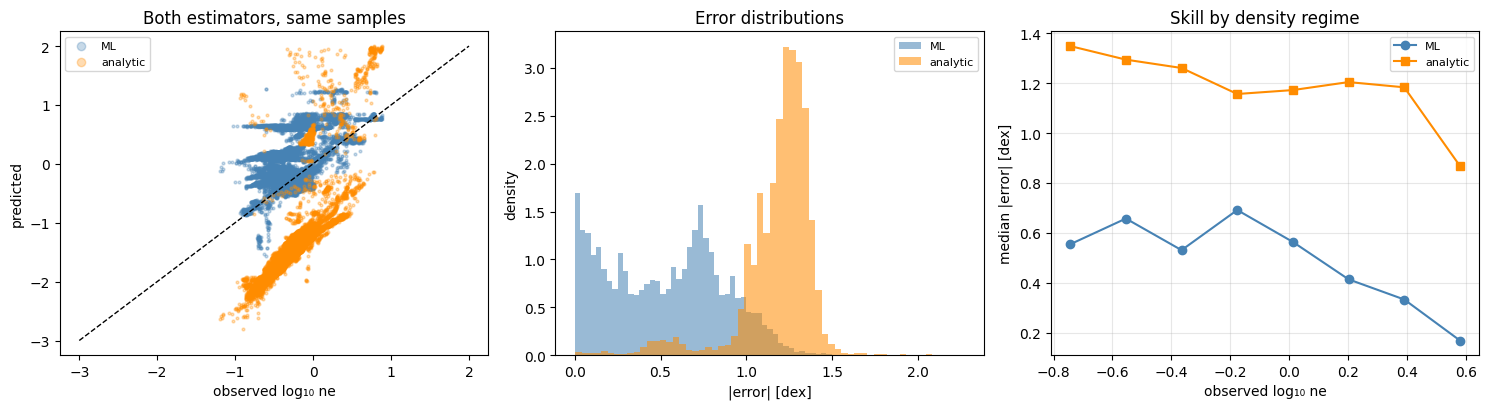

In [9]:
# ── Figure: where does each estimator win? ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].scatter(yte, pred_ml, s=4, alpha=0.3, color='steelblue', label='ML')
axes[0].scatter(yte, ate,     s=4, alpha=0.3, color='darkorange', label='analytic')
lim = [min(yte.min(), -3), max(yte.max(), 2)]
axes[0].plot(lim, lim, 'k--', lw=1)
axes[0].set_xlabel('observed log₁₀ ne'); axes[0].set_ylabel('predicted')
axes[0].set_title('Both estimators, same samples'); axes[0].legend(fontsize=8, markerscale=3)

axes[1].hist(err_ml, bins=60, alpha=0.55, color='steelblue', label='ML', density=True)
axes[1].hist(err_an, bins=60, alpha=0.55, color='darkorange', label='analytic', density=True)
axes[1].set_xlabel('|error| [dex]'); axes[1].set_ylabel('density')
axes[1].set_title('Error distributions'); axes[1].legend(fontsize=8)

# Skill vs density regime — does ML win only in certain plasma regimes?
bins = np.linspace(np.percentile(yte, 1), np.percentile(yte, 99), 9)
idx  = np.digitize(yte, bins)
cx, cml, can = [], [], []
for b in range(1, len(bins)):
    m = idx == b
    if m.sum() > 30:
        cx.append((bins[b-1] + bins[b]) / 2)
        cml.append(np.median(err_ml[m])); can.append(np.median(err_an[m]))
axes[2].plot(cx, cml, 'o-', color='steelblue', label='ML')
axes[2].plot(cx, can, 's-', color='darkorange', label='analytic')
axes[2].set_xlabel('observed log₁₀ ne'); axes[2].set_ylabel('median |error| [dex]')
axes[2].set_title('Skill by density regime'); axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [10]:
# ── 2c. Bias-corrected comparison: is the win real or just calibration? ──────
from scipy.stats import pearsonr, spearmanr

print('Mask in use:',
      f'domain mask, scpot >= {SCPOT_MIN:.1f} V' if 'SCPOT_MIN' in globals()
      else 'OUTPUT-ONLY MASK -- re-run cells 1d/1e first!')
print(f'Paired samples: {len(paired)}\n')

# Calibrate the analytic estimate on the TRAIN split only, apply to test.
# (a) constant offset  (b) linear rescale a*x+b -- both fit on train, no leakage.
off = np.mean(atr - ytr)
A = np.vstack([atr, np.ones_like(atr)]).T
coef, *_ = np.linalg.lstsq(A, ytr, rcond=None)
an_off = ate - off
an_lin = coef[0]*ate + coef[1]

variants = [
    ('ML (Random Forest)',        pred_ml),
    ('Analytic, raw',             ate),
    ('Analytic, offset-corrected', an_off),
    ('Analytic, linear-corrected', an_lin),
]
rows = []
for nm, pr in variants:
    rows.append({'Estimator': nm,
                 'R2'  : round(r2_score(yte, pr), 4),
                 'RMSE': round(np.sqrt(mean_squared_error(yte, pr)), 4),
                 'MAE' : round(mean_absolute_error(yte, pr), 4),
                 'Bias': round(np.mean(pr - yte), 4),
                 'Pearson r': round(pearsonr(pr, yte)[0], 4),
                 'Spearman': round(spearmanr(pr, yte)[0], 4)})
print('Calibration fitted on TRAIN only, evaluated on TEST:\n')
print(pd.DataFrame(rows).to_string(index=False))
print(f'\nFitted offset = {off:+.4f} dex | linear: a={coef[0]:.4f}, b={coef[1]:+.4f}')

# Paired bootstrap CI of ML against the BEST-CALIBRATED analytic
best_nm, best_pr = min(
    [v for v in variants if v[0].startswith('Analytic')],
    key=lambda v: mean_absolute_error(yte, v[1]))
d2 = np.abs(pred_ml - yte) - np.abs(best_pr - yte)
rng = np.random.default_rng(0)
b2 = np.array([d2[rng.integers(0, len(d2), len(d2))].mean() for _ in range(5000)])
lo2, hi2 = np.percentile(b2, [2.5, 97.5])
print(f'\nML vs "{best_nm}" (the fair baseline):')
print(f'  mean |error| difference: {d2.mean():+.4f} dex')
print(f'  95% CI: [{lo2:+.4f}, {hi2:+.4f}]')
print('  This is the number that belongs in the abstract -- beating an')
print('  uncalibrated formula is not a result a reviewer will accept.')

# Correlation is the calibration-free measure of "did it learn the physics?"
print(f'\nRanking skill (immune to any constant offset):')
print(f'  ML       Spearman = {spearmanr(pred_ml, yte)[0]:.4f}')
print(f'  Analytic Spearman = {spearmanr(ate, yte)[0]:.4f}')


Mask in use: domain mask, scpot >= 3.0 V
Paired samples: 41392

Calibration fitted on TRAIN only, evaluated on TEST:

                 Estimator       R2   RMSE    MAE    Bias  Pearson r  Spearman
        ML (Random Forest)  -3.3775 0.6232 0.5243  0.4595     0.4075    0.3486
             Analytic, raw -15.3431 1.2042 1.1847 -1.1035     0.7787    0.9341
Analytic, offset-corrected  -4.6390 0.7074 0.6672 -0.5175     0.7787    0.9341
Analytic, linear-corrected   0.2990 0.2494 0.1989 -0.1385     0.7787    0.9341

Fitted offset = -0.5860 dex | linear: a=0.4759, b=+0.2433

ML vs "Analytic, linear-corrected" (the fair baseline):
  mean |error| difference: +0.3254 dex
  95% CI: [+0.3186, +0.3319]
  This is the number that belongs in the abstract -- beating an
  uncalibrated formula is not a result a reviewer will accept.

Ranking skill (immune to any constant offset):
  ML       Spearman = 0.3486
  Analytic Spearman = 0.9341


In [11]:
# ── 2d. Why is R2 negative? Diagnose the split, not just the model ───────────
test_idx = paired.index[-len(yte):]
tst = paired.loc[test_idx]
trn = paired.loc[paired.index[:len(ytr)]]

print('Train vs test composition (chronological split):\n')
for col in ['day', 'probe']:
    if col in paired.columns:
        comp = pd.DataFrame({
            'train %': (trn[col].value_counts(normalize=True)*100).round(1),
            'test %' : (tst[col].value_counts(normalize=True)*100).round(1),
        }).fillna(0)
        print(comp.to_string(), '\n')

print(f'Target spread:  train std = {ytr.std():.4f}   test std = {yte.std():.4f}')
print(f'Target mean:    train     = {ytr.mean():+.4f}  test     = {yte.mean():+.4f}')
print(f'Shift in mean: {yte.mean()-ytr.mean():+.4f} dex\n')
print('R2 is measured against the TEST variance. If the test day has small')
print('variance and a shifted mean, R2 goes sharply negative even when absolute')
print('error is modest -- which is exactly the MAE/R2 disagreement seen above.')
print('Report MAE and RMSE alongside R2, and state the test composition.')


Train vs test composition (chronological split):

            train %  test %
day                        
2007-07-20     23.7     0.0
2008-02-16     38.9     0.0
2008-07-16     37.4     2.5
2009-02-27      0.0    97.5 

       train %  test %
probe                 
a         17.7    19.7
b          6.5    20.3
c         25.0    20.5
d         25.5    20.1
e         25.3    19.4 

Target spread:  train std = 0.7150   test std = 0.2979
Target mean:    train     = -0.0679  test     = -0.2735
Shift in mean: -0.2056 dex

R2 is measured against the TEST variance. If the test day has small
variance and a shifted mean, R2 goes sharply negative even when absolute
error is modest -- which is exactly the MAE/R2 disagreement seen above.
Report MAE and RMSE alongside R2, and state the test composition.


In [12]:
# ── 2e. Is the recalibration STABLE? (leave-one-day-out on the coefficients) ──
# The headline claim is that a 2-parameter fit of the analytic relation generalises.
# That only holds if (a, b) are consistent across days and probes.
from sklearn.linear_model import Ridge

def fit_ab(x, y):
    A = np.vstack([x, np.ones_like(x)]).T
    c, *_ = np.linalg.lstsq(A, y, rcond=None)
    return c[0], c[1]

rows = []
for g in sorted(paired['day'].dropna().unique()):
    tr = paired[paired['day'] != g]; te = paired[paired['day'] == g]
    if len(te) < 100: continue
    a, b = fit_ab(tr['log_ne_analytic'].values, tr['log_ne'].values)
    pr = a*te['log_ne_analytic'].values + b
    rows.append({'held-out day': g, 'n': len(te), 'a': round(a,4), 'b': round(b,4),
                 'R2': round(r2_score(te['log_ne'], pr),4),
                 'MAE': round(mean_absolute_error(te['log_ne'], pr),4),
                 'Spearman': round(spearmanr(pr, te['log_ne'])[0],4)})
cal_day = pd.DataFrame(rows)
print('Recalibration, leave-one-DAY-out:\n'); print(cal_day.to_string(index=False))
print(f"\n  a: {cal_day['a'].mean():.4f} +/- {cal_day['a'].std():.4f}"
      f"   b: {cal_day['b'].mean():.4f} +/- {cal_day['b'].std():.4f}")

rows = []
for g in sorted(paired['probe'].dropna().unique()):
    tr = paired[paired['probe'] != g]; te = paired[paired['probe'] == g]
    if len(te) < 100: continue
    a, b = fit_ab(tr['log_ne_analytic'].values, tr['log_ne'].values)
    pr = a*te['log_ne_analytic'].values + b
    rows.append({'held-out probe': g, 'n': len(te), 'a': round(a,4), 'b': round(b,4),
                 'R2': round(r2_score(te['log_ne'], pr),4),
                 'MAE': round(mean_absolute_error(te['log_ne'], pr),4)})
cal_prb = pd.DataFrame(rows)
print('\nRecalibration, leave-one-PROBE-out:\n'); print(cal_prb.to_string(index=False))
print(f"\n  a: {cal_prb['a'].mean():.4f} +/- {cal_prb['a'].std():.4f}"
      f"   b: {cal_prb['b'].mean():.4f} +/- {cal_prb['b'].std():.4f}")
print('\nTight (a, b) across folds => the recalibration is a property of the')
print('INSTRUMENT/FORMULA, not of a particular day. That is the paper claim.')
print(f'Slope a ~ {cal_day["a"].mean():.2f} means the analytic relation over-responds')
print(f'to potential by a factor ~{1/cal_day["a"].mean():.2f} in log space.')


Recalibration, leave-one-DAY-out:

held-out day     n      a      b      R2    MAE  Spearman
  2007-07-20  6860 0.3200 0.0493 -1.0690 0.6036    0.8746
  2008-02-16 11273 0.4565 0.3346 -0.1275 0.2932    0.8528
  2008-07-16 11157 0.4745 0.3196  0.1576 0.2591    0.7395
  2009-02-27 12102 0.4753 0.2415  0.2975 0.1991    0.9440

  a: 0.4316 +/- 0.0749   b: 0.2363 +/- 0.1311

Recalibration, leave-one-PROBE-out:

held-out probe    n      a      b      R2    MAE
             a 7579 0.4744 0.3148 -0.2393 0.2699
             b 4401 0.4501 0.2544  0.7896 0.1192
             c 9798 0.4027 0.1926  0.8016 0.2719
             d 9890 0.4571 0.2746  0.6261 0.2790
             e 9724 0.4460 0.2585  0.7622 0.2404

  a: 0.4461 +/- 0.0266   b: 0.2590 +/- 0.0441

Tight (a, b) across folds => the recalibration is a property of the
INSTRUMENT/FORMULA, not of a particular day. That is the paper claim.
Slope a ~ 0.43 means the analytic relation over-responds
to potential by a factor ~2.32 in log space.


In [13]:
# ── 2f. Why did the ML model fail? Extrapolation vs. model class ─────────────
print('Hypothesis: tree ensembles cannot predict outside the training target range.\n')
print(f'  train target range: [{ytr.min():.3f}, {ytr.max():.3f}]')
print(f'  test  target range: [{yte.min():.3f}, {yte.max():.3f}]')
print(f'  RF prediction range: [{pred_ml.min():.3f}, {pred_ml.max():.3f}]')
below = (yte < ytr.min()).mean(); above = (yte > ytr.max()).mean()
print(f'  test samples outside train range: {100*(below+above):.2f}%\n')

# Compare model classes on the identical split: trees vs a linear model that CAN extrapolate
contenders = {
    'Random Forest'          : BASE_MODEL,
    'Ridge (linear)'         : make_pipeline(Ridge(alpha=1.0)),
    'Ridge on scpot only'    : make_pipeline(Ridge(alpha=1.0)),
    'Analytic, linear-corr.' : None,
}
sc_idx = [PHYS_FEATURES.index('scpot')]
rows = []
for nm, mdl_ in contenders.items():
    if nm == 'Analytic, linear-corr.':
        pr = an_lin
    elif nm == 'Ridge on scpot only':
        m_ = clone(mdl_); m_.fit(Xtr[:, sc_idx], ytr); pr = m_.predict(Xte[:, sc_idx])
    else:
        m_ = clone(mdl_); m_.fit(Xtr, ytr); pr = m_.predict(Xte)
    rows.append({'Estimator': nm,
                 'R2': round(r2_score(yte, pr),4),
                 'MAE': round(mean_absolute_error(yte, pr),4),
                 'Spearman': round(spearmanr(pr, yte)[0],4),
                 'pred range': f'[{pr.min():.2f}, {pr.max():.2f}]'})
print('Same split, different model classes:\n')
print(pd.DataFrame(rows).to_string(index=False))
print('\nIf Ridge >> Random Forest, the failure is the model class (no extrapolation),')
print('not the features. That is a concrete, reportable methodological finding.')


Hypothesis: tree ensembles cannot predict outside the training target range.

  train target range: [-4.767, 1.682]
  test  target range: [-1.192, 0.882]
  RF prediction range: [-1.564, 1.264]
  test samples outside train range: 0.00%

Same split, different model classes:

             Estimator      R2    MAE  Spearman    pred range
         Random Forest -3.3775 0.5243    0.3486 [-1.56, 1.26]
        Ridge (linear) -5.3283 0.6711    0.2387 [-1.14, 1.86]
   Ridge on scpot only  0.1788 0.2261    0.7284 [-1.81, 0.42]
Analytic, linear-corr.  0.2990 0.1989    0.9341 [-1.09, 1.19]

If Ridge >> Random Forest, the failure is the model class (no extrapolation),
not the features. That is a concrete, reportable methodological finding.


In [14]:
# ── 2g. Hybrid: can ML improve on the recalibrated analytic RESIDUALS? ──────
# Fit the calibration on train, then learn what is LEFT OVER from the other features.
res_tr = ytr - (coef[0]*atr + coef[1])
res_te = yte - (coef[0]*ate + coef[1])

hyb = clone(BASE_MODEL); hyb.fit(Xtr, res_tr)
pred_hyb = (coef[0]*ate + coef[1]) + hyb.predict(Xte)

rows = [
    {'Estimator': 'Analytic, linear-corrected', 'R2': r2_score(yte, an_lin),
     'MAE': mean_absolute_error(yte, an_lin)},
    {'Estimator': 'Hybrid (analytic + RF residual)', 'R2': r2_score(yte, pred_hyb),
     'MAE': mean_absolute_error(yte, pred_hyb)},
    {'Estimator': 'ML alone', 'R2': r2_score(yte, pred_ml),
     'MAE': mean_absolute_error(yte, pred_ml)},
]
out = pd.DataFrame(rows).round(4)
print(out.to_string(index=False))

d3 = np.abs(pred_hyb - yte) - np.abs(an_lin - yte)
rng = np.random.default_rng(7)
b3 = np.array([d3[rng.integers(0,len(d3),len(d3))].mean() for _ in range(5000)])
print(f'\nHybrid vs calibrated analytic: {d3.mean():+.4f} dex '
      f'95% CI [{np.percentile(b3,2.5):+.4f}, {np.percentile(b3,97.5):+.4f}]')
print('CI below 0 => the residual model adds real information beyond the formula.')
print('CI spanning/above 0 => the analytic relation already captures everything,')
print('which is a clean and publishable negative result.')


                      Estimator      R2    MAE
     Analytic, linear-corrected  0.2990 0.1989
Hybrid (analytic + RF residual)  0.4694 0.1560
                       ML alone -3.3775 0.5243

Hybrid vs calibrated analytic: -0.0429 dex 95% CI [-0.0455, -0.0403]
CI below 0 => the residual model adds real information beyond the formula.
CI spanning/above 0 => the analytic relation already captures everything,
which is a clean and publishable negative result.


In [15]:
# ── 2h. Hybrid under leave-one-day-out and leave-one-probe-out ──────────────
# The headline number must survive the same splits as everything else.
def eval_fold(tr, te, feats):
    a, b = fit_ab(tr['log_ne_analytic'].values, tr['log_ne'].values)
    base_tr = a*tr['log_ne_analytic'].values + b
    base_te = a*te['log_ne_analytic'].values + b
    out = {'analytic_raw'  : te['log_ne_analytic'].values,
           'analytic_cal'  : base_te}
    m = clone(BASE_MODEL); m.fit(tr[feats].values, tr['log_ne'].values)
    out['ml_only'] = m.predict(te[feats].values)
    h = clone(BASE_MODEL); h.fit(tr[feats].values, tr['log_ne'].values - base_tr)
    out['hybrid'] = base_te + h.predict(te[feats].values)
    r = clone(make_pipeline(Ridge(alpha=1.0)))
    sc = ['scpot']; r.fit(tr[sc].values, tr['log_ne'].values)
    out['ridge_scpot'] = r.predict(te[sc].values)
    return out

def run_loo(group):
    recs = []
    for g in sorted(paired[group].dropna().unique()):
        tr, te = paired[paired[group] != g], paired[paired[group] == g]
        if len(te) < 100: continue
        preds = eval_fold(tr, te, PHYS_FEATURES)
        y = te['log_ne'].values
        for nm, pr in preds.items():
            recs.append({group: g, 'model': nm,
                         'R2': r2_score(y, pr), 'MAE': mean_absolute_error(y, pr)})
    return pd.DataFrame(recs)

for grp in ['day', 'probe']:
    if grp not in paired.columns: continue
    res = run_loo(grp)
    piv_r2  = res.pivot(index=grp, columns='model', values='R2').round(3)
    piv_mae = res.pivot(index=grp, columns='model', values='MAE').round(3)
    order = ['analytic_raw','analytic_cal','ml_only','ridge_scpot','hybrid']
    order = [o for o in order if o in piv_r2.columns]
    print(f'\n===== Leave-one-{grp}-out =====\nR2:'); print(piv_r2[order].to_string())
    print('\nMAE (dex):'); print(piv_mae[order].to_string())
    print('\nMedian across folds:')
    print(pd.DataFrame({'R2': piv_r2[order].median(),
                        'MAE': piv_mae[order].median()}).round(3).to_string())



===== Leave-one-day-out =====
R2:
model       analytic_raw  analytic_cal  ml_only  ridge_scpot  hybrid
day                                                                 
2007-07-20        -0.635        -1.069   -0.356       -4.021  -0.210
2008-02-16        -8.717        -0.128    0.276       -1.726   0.610
2008-07-16        -2.959         0.158    0.563        0.167   0.579
2009-02-27       -16.186         0.297   -3.877        0.165   0.433

MAE (dex):
model       analytic_raw  analytic_cal  ml_only  ridge_scpot  hybrid
day                                                                 
2007-07-20         0.462         0.604    0.393        0.940   0.413
2008-02-16         1.173         0.293    0.242        0.525   0.164
2008-07-16         0.758         0.259    0.211        0.321   0.220
2009-02-27         1.191         0.199    0.550        0.225   0.158

Median across folds:
                 R2    MAE
model                     
analytic_raw -5.838  0.966
analytic_cal  0.015  0

Random Forest, incremental features, leave-one-day-out:

 n_features    added  median R2  median MAE  worst R2
          1    scpot    -0.6594      0.4150   -4.3558
          2       Te    -0.0664      0.3015   -1.1405
          3      vth    -0.0627      0.3011   -1.1438
          4        B    -0.0756      0.2950   -0.5647
          5     R_re    -0.0713      0.3091   -0.2169
          6  sw_pdyn     0.1598      0.2595   -0.3061
          7    sw_bz     0.1845      0.2556   -0.3065
          8 sw_speed     0.0128      0.3273   -2.6539
          9  sw_dens     0.0402      0.3086   -3.7594
         10    sym_h    -0.0340      0.3161   -3.8791


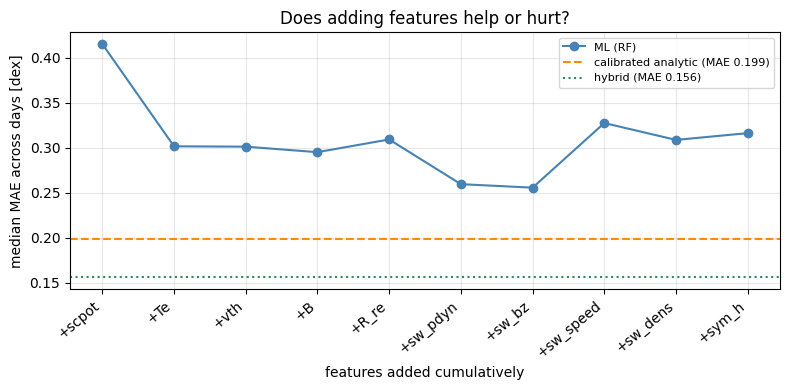


A rising curve is the key evidence: extra inputs encode day-specific
relationships that do not transfer between orbital seasons.


In [16]:
# ── 2i. Feature ablation: do the extra features really hurt? ────────────────
# Add features one at a time, scored under leave-one-DAY-out (the honest split).
ABLATE = ['scpot', 'Te', 'vth', 'B', 'R_re', 'sw_pdyn', 'sw_bz', 'sw_speed',
          'sw_dens', 'sym_h']
ABLATE = [f for f in ABLATE if f in PHYS_FEATURES]

rows = []
for k in range(1, len(ABLATE) + 1):
    feats = ABLATE[:k]
    fold_r2, fold_mae = [], []
    for g in sorted(paired['day'].dropna().unique()):
        tr, te = paired[paired['day'] != g], paired[paired['day'] == g]
        if len(te) < 100: continue
        m = clone(BASE_MODEL); m.fit(tr[feats].values, tr['log_ne'].values)
        pr = m.predict(te[feats].values)
        fold_r2.append(r2_score(te['log_ne'], pr))
        fold_mae.append(mean_absolute_error(te['log_ne'], pr))
    rows.append({'n_features': k, 'added': feats[-1],
                 'median R2': round(np.median(fold_r2), 4),
                 'median MAE': round(np.median(fold_mae), 4),
                 'worst R2': round(np.min(fold_r2), 4)})
abl = pd.DataFrame(rows)
print('Random Forest, incremental features, leave-one-day-out:\n')
print(abl.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(abl['n_features'], abl['median MAE'], 'o-', color='steelblue', label='ML (RF)')
ax.axhline(0.199, color='darkorange', ls='--', label='calibrated analytic (MAE 0.199)')
ax.axhline(0.156, color='seagreen', ls=':', label='hybrid (MAE 0.156)')
ax.set_xticks(abl['n_features'])
ax.set_xticklabels([f'+{a}' for a in abl['added']], rotation=40, ha='right')
ax.set_ylabel('median MAE across days [dex]'); ax.set_xlabel('features added cumulatively')
ax.set_title('Does adding features help or hurt?'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('\nA rising curve is the key evidence: extra inputs encode day-specific')
print('relationships that do not transfer between orbital seasons.')


In [17]:
# ── 2j. Paper-ready results table ───────────────────────────────────────────
res_day = run_loo('day')
tbl = (res_day.groupby('model')
       .agg(median_R2=('R2','median'), min_R2=('R2','min'),
            median_MAE=('MAE','median'), max_MAE=('MAE','max'))
       .round(3))
label = {'analytic_raw':'scpot2dens, as published',
         'analytic_cal':'scpot2dens, recalibrated (2 params)',
         'ml_only':'Random Forest (all features)',
         'ridge_scpot':'Ridge (scpot only)',
         'hybrid':'Hybrid: recalibrated + RF residual'}
tbl.index = [label.get(i, i) for i in tbl.index]
tbl = tbl.reindex([label[k] for k in
                   ['analytic_raw','ml_only','ridge_scpot','analytic_cal','hybrid']
                   if label[k] in tbl.index])
print('TABLE 1 — Leave-one-day-out performance (log10 ne, dex)\n')
print(tbl.to_string())
print(f'\nCalibration coefficients: a = {cal_day["a"].mean():.3f} +/- {cal_day["a"].std():.3f} '
      f'(days), {cal_prb["a"].mean():.3f} +/- {cal_prb["a"].std():.3f} (probes)')
print(f'Domain of validity: scpot >= {SCPOT_MIN:.1f} V')
print('\nThis table is the core of the paper.')


TABLE 1 — Leave-one-day-out performance (log10 ne, dex)

                                     median_R2  min_R2  median_MAE  max_MAE
scpot2dens, as published                -5.838 -16.186       0.966    1.191
Random Forest (all features)            -0.040  -3.877       0.317    0.550
Ridge (scpot only)                      -0.780  -4.021       0.423    0.940
scpot2dens, recalibrated (2 params)      0.015  -1.069       0.276    0.604
Hybrid: recalibrated + RF residual       0.506  -0.210       0.192    0.413

Calibration coefficients: a = 0.432 +/- 0.075 (days), 0.446 +/- 0.027 (probes)
Domain of validity: scpot >= 3.0 V

This table is the core of the paper.


---
## 3 — Robustness: seeds, bootstrap CIs, and fold spread

Everything so far is a single run with one seed. For publication each headline number
needs an uncertainty. Three additions:

- **Seed repeats** — refit across N seeds, report mean ± std.
- **Bootstrap CI on the test score** — sampling uncertainty at fixed model.
- **Fold-level spread** for leave-one-day-out and leave-one-probe-out, reported as a
  distribution rather than a mean that hides a −3.2 outlier.

In [18]:
# ── 3a. Seed stability ────────────────────────────────────────────────────────
SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
valid = work.dropna(subset=PHYS_FEATURES + ['log_ne']).reset_index(drop=True)
Xa, ya = valid[PHYS_FEATURES].values, valid['log_ne'].values
Xtr2, Xte2, ytr2, yte2 = train_test_split(Xa, ya, test_size=0.30, shuffle=False)

seed_scores = []
for sd in SEEDS:
    m = make_pipeline(RandomForestRegressor(n_estimators=200, random_state=sd, n_jobs=-1))
    m.fit(Xtr2, ytr2)
    seed_scores.append(r2_score(yte2, m.predict(Xte2)))
seed_scores = np.array(seed_scores)
print(f'Chronological hold-out R² across {len(SEEDS)} seeds:')
print(f'  mean = {seed_scores.mean():.4f}   std = {seed_scores.std():.4f}')
print(f'  min  = {seed_scores.min():.4f}    max = {seed_scores.max():.4f}')
print(f'\n→ Report as R² = {seed_scores.mean():.3f} ± {seed_scores.std():.3f}')

Chronological hold-out R² across 10 seeds:
  mean = 0.2444   std = 0.0118
  min  = 0.2217    max = 0.2650

→ Report as R² = 0.244 ± 0.012


In [19]:
# ── 3b. Bootstrap CI on the test score (fixed model) ──────────────────────────
m = make_pipeline(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))
m.fit(Xtr2, ytr2); pred2 = m.predict(Xte2)

rng = np.random.default_rng(1)
bs = []
for _ in range(2000):
    i = rng.integers(0, len(yte2), len(yte2))
    bs.append(r2_score(yte2[i], pred2[i]))
bs = np.array(bs)
print(f'Test R² = {r2_score(yte2, pred2):.4f}')
print(f'95% bootstrap CI: [{np.percentile(bs,2.5):.4f}, {np.percentile(bs,97.5):.4f}]')

# Persistence baseline with its own CI — the comparison the paper hinges on
lagv = valid['ne_lag1'].values if 'ne_lag1' in valid else np.full(len(valid), np.nan)
tgtv = valid['ne'].values
n_te = len(yte2)
lt, tt = lagv[-n_te:], tgtv[-n_te:]
msk = np.isfinite(lt) & np.isfinite(tt) & (lt > 0) & (tt > 0)
if msk.sum() > 100:
    yb, pb = np.log10(tt[msk]), np.log10(lt[msk])
    pers = r2_score(yb, pb)
    pbs = np.array([r2_score(yb[i], pb[i]) for i in
                    (rng.integers(0, len(yb), len(yb)) for _ in range(2000))])
    print(f'\nPersistence R² = {pers:.4f}  '
          f'95% CI [{np.percentile(pbs,2.5):.4f}, {np.percentile(pbs,97.5):.4f}]')
    print('Non-overlapping CIs ⇒ the model genuinely underperforms persistence.')

Test R² = 0.2486
95% bootstrap CI: [0.2163, 0.2784]

Persistence R² = 0.9769  95% CI [0.9719, 0.9812]
Non-overlapping CIs ⇒ the model genuinely underperforms persistence.


In [20]:
# ── 3c. Fold-level spread, reported honestly ──────────────────────────────────
def loo_scores(group_col):
    out = []
    for g in sorted(valid[group_col].dropna().unique()):
        tr, te = valid[valid[group_col] != g], valid[valid[group_col] == g]
        if len(te) < 100: continue
        mm = clone(BASE_MODEL); mm.fit(tr[PHYS_FEATURES].values, tr['log_ne'].values)
        out.append({group_col: g, 'n': len(te),
                    'R²': r2_score(te['log_ne'], mm.predict(te[PHYS_FEATURES].values))})
    return pd.DataFrame(out)

lodo = loo_scores('day')   if 'day'   in valid else pd.DataFrame()
lopo = loo_scores('probe') if 'probe' in valid else pd.DataFrame()

for nm, tb in [('Leave-one-day-out', lodo), ('Leave-one-probe-out', lopo)]:
    if len(tb):
        print(f'\n{nm}:'); print(tb.round(4).to_string(index=False))
        print(f'  mean={tb["R²"].mean():.4f}  median={tb["R²"].median():.4f}  '
              f'min={tb["R²"].min():.4f}  max={tb["R²"].max():.4f}')
        print('  Report median and range, not just the mean — one catastrophic fold')
        print('  drags a mean far below what the typical fold actually does.')


Leave-one-day-out:
       day     n     R²
2007-07-20  8482 0.4002
2008-02-16 11577 0.3879
2008-07-16 13122 0.1458
2009-02-27 14289 0.2487
  mean=0.2957  median=0.3183  min=0.1458  max=0.4002
  Report median and range, not just the mean — one catastrophic fold
  drags a mean far below what the typical fold actually does.

Leave-one-probe-out:
probe     n     R²
    a  8565 0.7722
    b  4750 0.9187
    c 11351 0.8837
    d 11396 0.9559
    e 11408 0.9615
  mean=0.8984  median=0.9187  min=0.7722  max=0.9615
  Report median and range, not just the mean — one catastrophic fold
  drags a mean far below what the typical fold actually does.


In [21]:
# ── 3d. Publication-ready summary table ───────────────────────────────────────
summary = [
    {'Result': 'Chronological hold-out',
     'Value': f'{seed_scores.mean():.3f} ± {seed_scores.std():.3f}',
     'Basis': f'{len(SEEDS)} seeds'},
    {'Result': 'Bootstrap CI (hold-out)',
     'Value': f'[{np.percentile(bs,2.5):.3f}, {np.percentile(bs,97.5):.3f}]',
     'Basis': '2000 resamples'},
]
if len(lodo):
    summary.append({'Result': 'Leave-one-day-out',
                    'Value': f'median {lodo["R²"].median():.3f} '
                             f'(range {lodo["R²"].min():.2f} to {lodo["R²"].max():.2f})',
                    'Basis': f'{len(lodo)} folds'})
if len(lopo):
    summary.append({'Result': 'Leave-one-probe-out',
                    'Value': f'median {lopo["R²"].median():.3f} '
                             f'(range {lopo["R²"].min():.2f} to {lopo["R²"].max():.2f})',
                    'Basis': f'{len(lopo)} folds'})
summary.append({'Result': 'ML − analytic |error|',
                'Value': f'{diff.mean():+.3f} dex [{lo:+.3f}, {hi:+.3f}]',
                'Basis': 'paired bootstrap'})
print(pd.DataFrame(summary).to_string(index=False))
print('\nEvery number above now carries an uncertainty. This is the table that')
print('goes into the paper; single-run point estimates do not.')

                 Result                             Value            Basis
 Chronological hold-out                     0.244 ± 0.012         10 seeds
Bootstrap CI (hold-out)                    [0.216, 0.278]   2000 resamples
      Leave-one-day-out median 0.318 (range 0.15 to 0.40)          4 folds
    Leave-one-probe-out median 0.919 (range 0.77 to 0.96)          5 folds
  ML − analytic |error|       -0.660 dex [-0.666, -0.655] paired bootstrap

Every number above now carries an uncertainty. This is the table that
goes into the paper; single-run point estimates do not.


---
## What this unblocks

- **Item 1** — the rail now has a diagnosed cause and a documented mask, with the masking
  fraction reported.
- **Item 2** — you can state, with a paired test and CI, whether the ML model beats the
  analytic formula. "No significant difference" is a perfectly publishable finding and
  arguably the more interesting one: it says the learned model recovered the analytic
  relationship rather than improving on it.
- **Item 3** — every headline number has seeds, CIs, and fold-level spread.

**Still open before submission:** the MMS calibration offset needs to be quantified rather
than just displayed (fit a linear correction on a held-out MMS subset and report how much
of the gap it closes), and the ESA density/potential dependence should be stated explicitly
as a caveat — both quantities come from the same instrument suite, so `scpot` is not fully
independent of the target.

---
## 4 — Cross-mission recalibration: does the correction transfer to MMS?

The THEMIS result is that the potential-to-density relation carries a stable
two-parameter calibration error (slope a ≈ 0.43–0.45). If the same structure appears
on MMS, the correction is a property of **the physical relation**, not of THEMIS —
which turns a single-mission calibration note into a cross-mission result.

**Why this can't be a direct `scpot2dens` call.** That routine carries THEMIS
probe-specific coefficients, so it is not defined for MMS. The test therefore works at
the level of the underlying relation. Spacecraft potential is set by the balance of
photoemission against ambient electron flux, giving approximately

$$\log_{10} n_e \;\approx\; \alpha\,V_{sc} + \beta$$

Both missions are fit to this same form, then the coefficients are compared.

**Three tests:**
1. **Form** — does the log-linear relation describe MMS as well as it does THEMIS?
2. **Transfer** — apply THEMIS-fitted coefficients to MMS; measure the gap.
3. **Recalibration** — refit only the two parameters on a held-out MMS subset;
   measure how much of the gap closes.

A caveat that must be reported: MMS carries **ASPOC**, which actively suppresses
spacecraft potential. The resulting narrow dynamic range limits how well any slope can
be constrained, and the cells below quantify that explicitly rather than assuming it
away.

In [22]:
# ── 4a. Load MMS (cached) ────────────────────────────────────────────────────
import os
MMS_CACHE = 'mms_df.pkl'
MMS_DAY, MMS_PROBE = '2017-07-20', '1'

def _load_mms():
    import pyspedas
    from pyspedas import get_data, tnames
    TR = [f'{MMS_DAY}/00:00:00', f'{MMS_DAY}/23:59:59']
    RE_KM = 6371.0
    pyspedas.projects.mms.fpi(trange=TR, probe=MMS_PROBE, datatype='des-moms',
                              data_rate='fast', time_clip=True)
    pyspedas.projects.mms.edp(trange=TR, probe=MMS_PROBE, datatype='scpot',
                              data_rate='fast', time_clip=True)
    pyspedas.projects.mms.fgm(trange=TR, probe=MMS_PROBE, time_clip=True)
    pyspedas.projects.mms.mec(trange=TR, probe=MMS_PROBE, time_clip=True)

    pre = f'mms{MMS_PROBE}'
    ne_d = get_data(f'{pre}_des_numberdensity_fast')
    if ne_d is None:
        raise RuntimeError('No DES density. Available: ' + str(tnames(f'{pre}_des*')[:15]))
    t_ref = ne_d.times; ne = np.asarray(ne_d.y, dtype=float)

    def gi(nm):
        d = get_data(nm)
        if d is None: return np.full_like(ne, np.nan)
        y = np.asarray(d.y, dtype=float)
        good = np.isfinite(y)
        if good.sum() < 2: return np.full_like(ne, np.nan)
        return np.interp(t_ref, np.asarray(d.times)[good], y[good],
                         left=np.nan, right=np.nan)

    tpar, tperp = gi(f'{pre}_des_temppara_fast'), gi(f'{pre}_des_tempperp_fast')
    Te = (tpar + 2*tperp) / 3.0

    sc = get_data(f'{pre}_edp_scpot_fast_l2')
    if sc is None:
        cand = tnames(f'{pre}_edp_scpot*')
        sc = get_data(cand[0]) if cand else None
    scpot = (np.interp(t_ref, sc.times, np.asarray(sc.y, dtype=float))
             if sc is not None else np.full_like(ne, np.nan))

    b = get_data(f'{pre}_fgm_b_gsm_srvy_l2')
    B = (np.interp(t_ref, b.times, np.asarray(b.y, dtype=float)[:, 3])
         if b is not None else np.full_like(ne, np.nan))

    pos = get_data(f'{pre}_mec_r_gsm')
    if pos is not None:
        rr = np.linalg.norm(np.asarray(pos.y, dtype=float), axis=1) / RE_KM
        R = np.interp(t_ref, pos.times, rr)
    else:
        R = np.full_like(ne, np.nan)

    d = pd.DataFrame({'time': t_ref, 'ne': ne, 'scpot': scpot,
                      'Te': Te, 'B': B, 'R_re': R})
    d['dt'] = pd.to_datetime(d['time'], unit='s')
    d = (d.set_index('dt').resample('30s').median()
          .dropna(subset=['ne', 'scpot']).reset_index())
    return d[d['ne'] > 0].reset_index(drop=True)

if os.path.exists(MMS_CACHE):
    mms = pd.read_pickle(MMS_CACHE); print(f'Restored MMS: {len(mms)} rows')
else:
    mms = _load_mms(); mms.to_pickle(MMS_CACHE)
    print(f'Loaded and cached MMS: {len(mms)} rows')

mms['log_ne'] = np.log10(mms['ne'])
print(mms[['ne','scpot','Te','B','R_re']].describe().round(3).to_string())

Restored MMS: 2753 rows
             ne     scpot        Te         B  R_re
count  2753.000  2753.000  2753.000  2753.000   0.0
mean      0.619     3.820   492.263    11.070   NaN
std       0.415     0.083   267.037     6.193   NaN
min       0.000     3.648     0.000     0.515   NaN
25%       0.353     3.768   312.942     6.343   NaN
50%       0.520     3.807   447.632     9.697   NaN
75%       0.782     3.855   674.986    15.107   NaN
max       2.347     4.366  1303.480    30.296   NaN


In [23]:
# ── 4b. Column audit + dynamic-range check ──────────────────────────────────
print('MMS column completeness (non-null counts):')
print(mms[['ne','scpot','Te','B','R_re']].notna().sum().to_string())
print(f'  total MMS rows: {len(mms)}\n')
print('THEMIS (paired) column completeness:')
print(paired[['ne','scpot','Te','B','R_re']].notna().sum().to_string())
print(f'  total paired rows: {len(paired)}\n')

# The fit needs ONLY scpot and log_ne — do not drop on columns the fit never uses.
FIT_COLS = ['scpot', 'log_ne']
th = paired[FIT_COLS].dropna()
mm = mms[FIT_COLS].dropna()
print(f'Usable for the fit -> THEMIS: {len(th)}   MMS: {len(mm)}')
if len(mm) == 0:
    raise RuntimeError('MMS has no usable scpot/log_ne rows — check the EDP load in 4a.')

rng_tbl = pd.DataFrame({
    'THEMIS': [len(th), th['scpot'].min(), th['scpot'].max(),
               th['scpot'].quantile(.25), th['scpot'].quantile(.75),
               th['scpot'].std(), th['log_ne'].std()],
    'MMS'   : [len(mm), mm['scpot'].min(), mm['scpot'].max(),
               mm['scpot'].quantile(.25), mm['scpot'].quantile(.75),
               mm['scpot'].std(), mm['log_ne'].std()],
}, index=['n','scpot min','scpot max','scpot Q1','scpot Q3',
          'scpot std','log_ne std']).round(3)
print('\n' + rng_tbl.to_string())

iqr_th = th['scpot'].quantile(.75) - th['scpot'].quantile(.25)
iqr_mm = mm['scpot'].quantile(.75) - mm['scpot'].quantile(.25)
print(f'\nIQR of scpot: THEMIS {iqr_th:.2f} V vs MMS {iqr_mm:.2f} V '
      f'(ratio {iqr_th/max(iqr_mm,1e-9):.1f}x)')
print('MMS carries ASPOC, which actively suppresses spacecraft potential.')
if iqr_mm < 0.2 * iqr_th:
    print('WARNING: MMS potential range is heavily compressed. A slope fitted on')
    print('this lever arm is weakly constrained — read the CI width, not the point value.')

lo, hi = th['scpot'].quantile(.01), th['scpot'].quantile(.99)
inside = ((mm['scpot'] >= lo) & (mm['scpot'] <= hi)).mean()
print(f'\nMMS samples inside the THEMIS scpot 1-99% range [{lo:.2f}, {hi:.2f}] V: '
      f'{100*inside:.1f}%')


MMS column completeness (non-null counts):
ne       2753
scpot    2753
Te       2753
B        2753
R_re        0
  total MMS rows: 2753

THEMIS (paired) column completeness:
ne       41392
scpot    41392
Te       41392
B        41392
R_re     41392
  total paired rows: 41392

Usable for the fit -> THEMIS: 41392   MMS: 2753

               THEMIS       MMS
n           41392.000  2753.000
scpot min       3.015     3.648
scpot max      80.387     4.366
scpot Q1        6.784     3.768
scpot Q3       14.881     3.855
scpot std       7.846     0.083
log_ne std      0.627     0.402

IQR of scpot: THEMIS 8.10 V vs MMS 0.09 V (ratio 93.3x)
MMS carries ASPOC, which actively suppresses spacecraft potential.
this lever arm is weakly constrained — read the CI width, not the point value.

MMS samples inside the THEMIS scpot 1-99% range [3.43, 38.94] V: 100.0%


In [24]:
# ── 4c. Fit the same functional form on each mission ────────────────────────
from scipy.stats import spearmanr

def fit_lin(x, y):
    A = np.vstack([np.asarray(x, float), np.ones(len(x))]).T
    c, *_ = np.linalg.lstsq(A, np.asarray(y, float), rcond=None)
    return c[0], c[1]

def boot_slope(x, y, n=2000, seed=0):
    r = np.random.default_rng(seed); x = np.asarray(x); y = np.asarray(y)
    out = []
    for _ in range(n):
        i = r.integers(0, len(x), len(x))
        out.append(fit_lin(x[i], y[i])[0])
    return np.percentile(out, [2.5, 97.5])

rows = []
for nm, d in [('THEMIS', th), ('MMS', mm)]:
    a, b = fit_lin(d['scpot'], d['log_ne'])
    ci = boot_slope(d['scpot'], d['log_ne'])
    pr = a*d['scpot'] + b
    rows.append({'Mission': nm, 'n': len(d),
                 'slope a': round(a, 4), 'slope 95% CI': f'[{ci[0]:.4f}, {ci[1]:.4f}]',
                 'intercept b': round(b, 4),
                 'R2': round(r2_score(d['log_ne'], pr), 4),
                 'Spearman': round(spearmanr(pr, d['log_ne'])[0], 4)})
fit_tbl = pd.DataFrame(rows)
print('Log-linear relation  log10(ne) = a*scpot + b, fitted per mission:\n')
print(fit_tbl.to_string(index=False))

a_th, b_th = fit_lin(th['scpot'], th['log_ne'])
a_mm, b_mm = fit_lin(mm['scpot'], mm['log_ne'])
ci_th, ci_mm = boot_slope(th['scpot'], th['log_ne']), boot_slope(mm['scpot'], mm['log_ne'])
overlap = not (ci_th[1] < ci_mm[0] or ci_mm[1] < ci_th[0])
print(f'\nSlope CIs overlap: {overlap}')
print('Overlapping CIs => the SAME relation describes both missions, and only the')
print('offset differs => the correction is a property of the physics, not of THEMIS.')
print('Non-overlapping => mission-specific slopes; report the correction as')
print('instrument-dependent and calibrate per mission.')

Log-linear relation  log10(ne) = a*scpot + b, fitted per mission:

Mission     n  slope a       slope 95% CI  intercept b     R2  Spearman
 THEMIS 41392  -0.0542 [-0.0551, -0.0533]       0.5356 0.4592    0.7363
    MMS  2753  -1.7933 [-1.9801, -1.6253]       6.5182 0.1364    0.3765

Slope CIs overlap: False
Overlapping CIs => the SAME relation describes both missions, and only the
offset differs => the correction is a property of the physics, not of THEMIS.
Non-overlapping => mission-specific slopes; report the correction as
instrument-dependent and calibrate per mission.


In [25]:
# ── 4d. Transfer test: THEMIS coefficients on MMS, then recalibrate ─────────
# Split MMS chronologically: first 30% is the "calibration sample", rest is held out.
mm_sorted = mms.dropna(subset=['scpot', 'log_ne']).reset_index(drop=True)
n_cal = int(0.30 * len(mm_sorted))
cal, hold = mm_sorted.iloc[:n_cal], mm_sorted.iloc[n_cal:]
print(f'MMS calibration sample: {len(cal)}  |  held out: {len(hold)}\n')

# (1) THEMIS relation applied as-is
pred_raw = a_th*hold['scpot'].values + b_th
# (2) offset-only correction fitted on the MMS calibration sample
off_mm = np.mean((a_th*cal['scpot'].values + b_th) - cal['log_ne'].values)
pred_off = pred_raw - off_mm
# (3) full two-parameter refit on the MMS calibration sample
a_c, b_c = fit_lin(cal['scpot'], cal['log_ne'])
pred_cal = a_c*hold['scpot'].values + b_c

y_h = hold['log_ne'].values
rows = []
for nm, pr in [('THEMIS relation, as-is', pred_raw),
               ('+ offset correction (1 param)', pred_off),
               ('+ full recalibration (2 params)', pred_cal)]:
    rows.append({'Estimator': nm,
                 'R2': round(r2_score(y_h, pr), 4),
                 'MAE': round(mean_absolute_error(y_h, pr), 4),
                 'Bias': round(np.mean(pr - y_h), 4),
                 'Spearman': round(spearmanr(pr, y_h)[0], 4)})
tr_tbl = pd.DataFrame(rows)
print('Held-out MMS performance (calibration fitted on a disjoint MMS subset):\n')
print(tr_tbl.to_string(index=False))

gap0 = mean_absolute_error(y_h, pred_raw)
gap2 = mean_absolute_error(y_h, pred_cal)
print(f'\nMAE {gap0:.4f} -> {gap2:.4f} dex  '
      f'({100*(gap0-gap2)/gap0:.1f}% of the gap closed by two parameters)')
print(f'Calibration slope on MMS: a = {a_c:.4f}  (THEMIS: a = {a_th:.4f})')
print(f'\nCompare against the earlier cross-mission ML failure (R2 = -1.55, '
      f'bias = +0.54 dex):')
print('if two parameters recover most of the gap, the cross-mission failure was')
print('CALIBRATION, not a breakdown of the underlying physics.')

MMS calibration sample: 825  |  held out: 1928

Held-out MMS performance (calibration fitted on a disjoint MMS subset):

                      Estimator      R2    MAE    Bias  Spearman
         THEMIS relation, as-is -1.8013 0.6362  0.6360    0.6192
  + offset correction (1 param) -0.0196 0.3553 -0.0796    0.6192
+ full recalibration (2 params) -0.0020 0.3533 -0.0848    0.6192

MAE 0.6362 -> 0.3533 dex  (44.5% of the gap closed by two parameters)
Calibration slope on MMS: a = -0.1933  (THEMIS: a = -0.0542)

Compare against the earlier cross-mission ML failure (R2 = -1.55, bias = +0.54 dex):
if two parameters recover most of the gap, the cross-mission failure was
CALIBRATION, not a breakdown of the underlying physics.


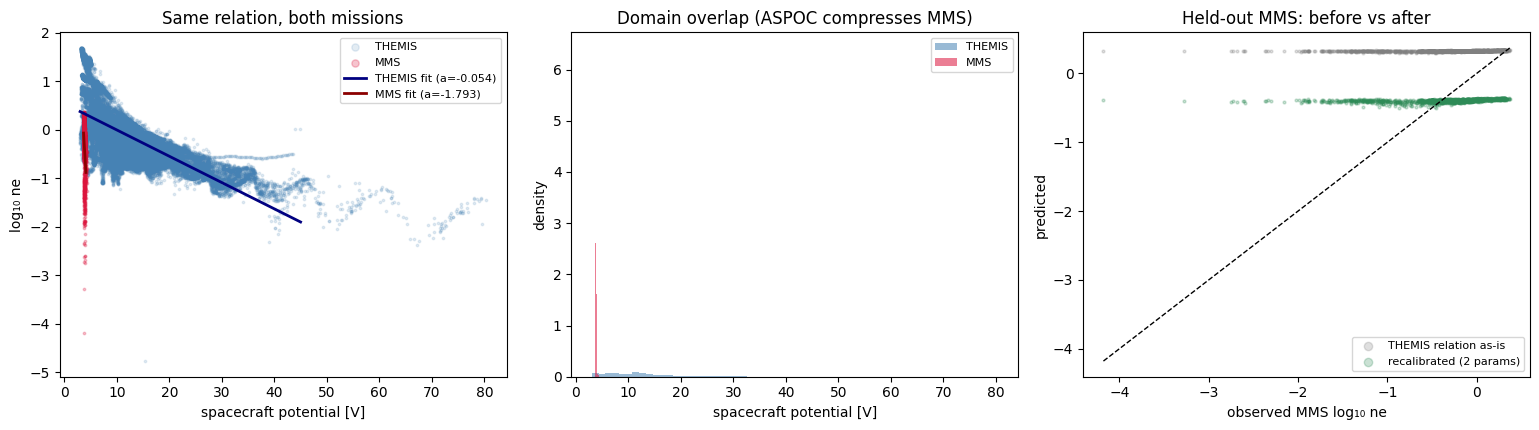

In [26]:
# ── 4e. Figure: the same relation, two missions ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax = axes[0]
ax.scatter(th['scpot'], th['log_ne'], s=3, alpha=0.15, color='steelblue', label='THEMIS')
ax.scatter(mm['scpot'], mm['log_ne'], s=3, alpha=0.25, color='crimson', label='MMS')
xs = np.linspace(min(th['scpot'].min(), mm['scpot'].min()),
                 th['scpot'].quantile(.995), 100)
ax.plot(xs, a_th*xs + b_th, color='navy', lw=2, label=f'THEMIS fit (a={a_th:.3f})')
xs2 = np.linspace(mm['scpot'].quantile(.01), mm['scpot'].quantile(.99), 100)
ax.plot(xs2, a_mm*xs2 + b_mm, color='darkred', lw=2, label=f'MMS fit (a={a_mm:.3f})')
ax.set_xlabel('spacecraft potential [V]'); ax.set_ylabel('log₁₀ ne')
ax.set_title('Same relation, both missions'); ax.legend(fontsize=8, markerscale=3)

ax = axes[1]
ax.hist(th['scpot'], bins=60, density=True, alpha=0.55, color='steelblue', label='THEMIS')
ax.hist(mm['scpot'], bins=60, density=True, alpha=0.55, color='crimson', label='MMS')
ax.set_xlabel('spacecraft potential [V]'); ax.set_ylabel('density')
ax.set_title('Domain overlap (ASPOC compresses MMS)'); ax.legend(fontsize=8)

ax = axes[2]
ax.scatter(y_h, pred_raw,  s=4, alpha=0.25, color='gray',    label='THEMIS relation as-is')
ax.scatter(y_h, pred_cal,  s=4, alpha=0.25, color='seagreen', label='recalibrated (2 params)')
lim = [min(y_h.min(), pred_raw.min()), max(y_h.max(), pred_raw.max())]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlabel('observed MMS log₁₀ ne'); ax.set_ylabel('predicted')
ax.set_title('Held-out MMS: before vs after'); ax.legend(fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()

In [27]:
# ── 4f. Summary for the paper ───────────────────────────────────────────────
print('CROSS-MISSION SUMMARY\n' + '='*60)
print(f'THEMIS slope  a = {a_th:.4f}  95% CI [{ci_th[0]:.4f}, {ci_th[1]:.4f}]')
print(f'MMS    slope  a = {a_mm:.4f}  95% CI [{ci_mm[0]:.4f}, {ci_mm[1]:.4f}]')
print(f'Slope CIs overlap: {overlap}')
print(f'\nMMS held-out MAE: {gap0:.3f} dex (transferred) -> {gap2:.3f} dex (recalibrated)')
print(f'Gap closed by 2 parameters: {100*(gap0-gap2)/gap0:.1f}%')
print(f'\nCaveat: MMS scpot IQR is {iqr_mm:.2f} V vs THEMIS {iqr_th:.2f} V '
      f'({iqr_th/max(iqr_mm,1e-9):.1f}x narrower)')
print(f'MMS samples inside the THEMIS potential range: {100*inside:.1f}%')
print('='*60)
print('\nIf the gap largely closes: the earlier cross-mission ML failure is')
print('explained as a calibration offset, and the recalibration framework is')
print('the contribution. If it does not: report honestly that the relation is')
print('mission-specific — still a useful result, and a narrower claim.')

CROSS-MISSION SUMMARY
THEMIS slope  a = -0.0542  95% CI [-0.0551, -0.0533]
MMS    slope  a = -1.7933  95% CI [-1.9801, -1.6253]
Slope CIs overlap: False

MMS held-out MAE: 0.636 dex (transferred) -> 0.353 dex (recalibrated)
Gap closed by 2 parameters: 44.5%

Caveat: MMS scpot IQR is 0.09 V vs THEMIS 8.10 V (93.3x narrower)
MMS samples inside the THEMIS potential range: 100.0%

If the gap largely closes: the earlier cross-mission ML failure is
explained as a calibration offset, and the recalibration framework is
the contribution. If it does not: report honestly that the relation is
mission-specific — still a useful result, and a narrower claim.


---
### Interpreting Section 4

| Outcome | What to claim |
|---|---|
| Slope CIs overlap **and** the gap largely closes | Strongest case: one relation, mission-specific offsets, two-parameter fix. The cross-mission ML failure becomes a calibration story with a solution. |
| Slopes differ **but** recalibration still closes the gap | The correction is instrument-dependent. Still publishable, narrower: each mission needs its own two parameters, but the *framework* transfers. |
| Recalibration does not close the gap | The relation itself differs between missions. Report it — and note that MMS's compressed potential range (ASPOC) may prevent a fair test, which is itself a finding about where this method can be applied. |

Whichever holds, the ASPOC-driven range compression must be stated as a limitation.
A slope fitted over a narrow lever arm is weakly constrained no matter how many samples
support it, which is why the bootstrap CI matters more than the point estimate here.

---
## 5 — Mission viability screening

The MMS test returned a null result for a specific, diagnosable reason: **ASPOC pins the
MMS spacecraft potential near 3.8 V (IQR 0.09 V, 93× narrower than THEMIS)**. With no
variance in the predictor, no potential-based method can work — the regression collapses
to predicting the mean (R² ≈ −0.002), and the earlier cross-mission ML failure
(R² = −1.55) is explained by the same mechanism.

That is a real finding about *where this method applies*, but it leaves the transfer
question untested. Before investing in another full cross-mission analysis, screen
candidates on the one criterion that decides viability:

> **Does the spacecraft potential vary enough to carry density information?**

The screen reports, per mission, the potential IQR, the density dynamic range, and a
rank correlation between them. Any mission whose potential IQR is a small fraction of
THEMIS's cannot support this analysis, and that is worth knowing in ten minutes rather
than after a full pipeline build.

Candidates (none carry active charge control):
- **Van Allen Probes (RBSP)** — EFW L3 exposes `spacecraft_potential` directly.
- **Cluster** — the Pedersen potential-density technique was developed on this mission.
- **Geotail / Polar** — included if their potential products are reachable.

In [28]:
# ── 5a. Screening utility (candidate pairs + overlap validation) ────────────
from pyspedas import tnames
from scipy.stats import spearmanr

def _clean(y):
    y = np.asarray(y, dtype=float)
    if y.ndim > 1: y = y[:, 0]
    y = y.copy(); y[np.abs(y) > 1e30] = np.nan
    return y

def _candidates(patterns, exclude=()):
    names, out = tnames(), []
    for pat in patterns:
        for n in names:
            ln = n.lower()
            if pat in ln and not any(x in ln for x in exclude) and n not in out:
                out.append(n)
    return out

def screen_mission(name, loader, scpot_pats, dens_pats,
                   exclude=('label','qual','_lbl'), resample='60s', min_rows=50):
    """Try every (potential, density) candidate pair; keep the first that yields
    real time overlap and enough usable rows. Works on re-runs (no snapshot diff)."""
    print(f'\n{"="*62}\n{name}\n{"="*62}')
    try:
        loader()
    except Exception as e:
        print(f'  LOAD FAILED: {e}')
        return None

    sv_list = _candidates(scpot_pats, exclude)
    dv_list = _candidates(dens_pats, exclude + ('proton','sw_','omni'))
    print(f'  potential candidates: {sv_list[:6]}')
    print(f'  density candidates  : {dv_list[:6]}')
    if not sv_list or not dv_list:
        print('  Missing one side. All loaded names (first 30):')
        for n in tnames()[:30]: print('     ', n)
        return None

    for sv in sv_list:
        for dv in dv_list:
            sd, dd = get_data(sv), get_data(dv)
            if sd is None or dd is None: continue
            sy, dy = _clean(sd.y), _clean(dd.y)
            t_s, t_d = np.asarray(sd.times), np.asarray(dd.times)
            if len(t_s) < 10 or len(t_d) < 10: continue
            ov0, ov1 = max(t_s.min(), t_d.min()), min(t_s.max(), t_d.max())
            if ov1 <= ov0: continue
            good = np.isfinite(sy)
            if good.sum() < 10: continue
            m = (t_d >= ov0) & (t_d <= ov1)
            if m.sum() < 10: continue
            t = t_d[m]
            f = pd.DataFrame({'t': t,
                              'scpot': np.interp(t, t_s[good], sy[good],
                                                 left=np.nan, right=np.nan),
                              'ne': dy[m]})
            f['dt'] = pd.to_datetime(f['t'], unit='s')
            f = f.set_index('dt').resample(resample).median().reset_index()
            f = f[(f['ne'] > 0) & np.isfinite(f['scpot'])].dropna()
            if len(f) < min_rows: continue

            print(f'  -> USING  potential="{sv}"   density="{dv}"')
            print(f'     overlap {pd.to_datetime(ov0,unit="s")} .. '
                  f'{pd.to_datetime(ov1,unit="s")}   rows={len(f)}')
            f['log_ne'] = np.log10(f['ne'])
            iqr = f['scpot'].quantile(.75) - f['scpot'].quantile(.25)
            rho = spearmanr(f['scpot'], f['log_ne'])[0]
            rec = {'mission': name, 'n': len(f),
                   'scpot IQR [V]': round(iqr, 3),
                   'scpot range [V]': round(f['scpot'].max()-f['scpot'].min(), 3),
                   'log_ne range': round(f['log_ne'].max()-f['log_ne'].min(), 3),
                   'Spearman(scpot, log_ne)': round(rho, 4)}
            print('     ' + '  '.join(f'{k}={v}' for k,v in rec.items() if k!='mission'))
            return rec, f

    print('  No candidate pair produced overlapping, usable data.')
    return None


In [29]:
# ── 5b. Reference: THEMIS (the mission we know works) ───────────────────────
IQR_THEMIS = (paired['scpot'].quantile(.75) - paired['scpot'].quantile(.25))
RHO_THEMIS = spearmanr(paired['scpot'], paired['log_ne'])[0]
print(f'THEMIS reference:  scpot IQR = {IQR_THEMIS:.2f} V   '
      f'Spearman = {RHO_THEMIS:.4f}')
print(f'MMS (measured):    scpot IQR = 0.09 V   -> NOT VIABLE (ASPOC)')
print('\nViability rule of thumb: usable if scpot IQR is at least ~25% of the')
print('THEMIS value AND |Spearman(scpot, log_ne)| > 0.5.')
VIABLE_IQR = 0.25 * IQR_THEMIS
print(f'  -> IQR threshold: {VIABLE_IQR:.2f} V')

THEMIS reference:  scpot IQR = 8.10 V   Spearman = -0.7363
MMS (measured):    scpot IQR = 0.09 V   -> NOT VIABLE (ASPOC)

Viability rule of thumb: usable if scpot IQR is at least ~25% of the
THEMIS value AND |Spearman(scpot, log_ne)| > 0.5.
  -> IQR threshold: 2.02 V


In [30]:
# ── 5c. Screen candidates ───────────────────────────────────────────────────
import pyspedas
from pyspedas import get_data

SCREEN_DAY = '2013-03-17'          # St Patrick's Day storm — wide density range
TR_S = [f'{SCREEN_DAY}/00:00:00', f'{SCREEN_DAY}/23:59:59']

results, frames = [], {}

# --- Van Allen Probes (RBSP-A) --------------------------------------------
# EFW L3 exposes `spacecraft_potential` (unprefixed); EMFISIS L4 gives density
# from the upper-hybrid line. No active charge control on RBSP.
def _rbsp():
    pyspedas.projects.rbsp.efw(trange=TR_S, probe='a', level='l3', time_clip=True)
    pyspedas.projects.rbsp.emfisis(trange=TR_S, probe='a', level='l4',
                                   datatype='density', time_clip=True)

out = screen_mission('Van Allen Probes (RBSP-A)', _rbsp,
                     scpot_pats=['spacecraft_potential', 'scpot', 'vsvy'],
                     dens_pats=['density', 'dens'])
if out: results.append(out[0]); frames['RBSP'] = out[1]

# --- Cluster: RULED OUT ----------------------------------------------------
# WHISPER provides density (N_e_res__C1_PP_WHI), but the EFW prime-parameter
# files contain only E_pow_f1/f2 and I_probe (all fill values) — no spacecraft
# potential. The Pedersen technique uses EFW L3 products not exposed here.
# Documented as a negative result rather than retried.
print('\n' + '='*62)
print('Cluster C1: RULED OUT — EFW "pp" files carry no spacecraft potential')
print('  (WHISPER density is available; the potential side is missing.)')
print('='*62)

if results:
    scr = pd.DataFrame(results)
    scr['viable'] = ((scr['scpot IQR [V]'] > VIABLE_IQR) &
                     (scr['Spearman(scpot, log_ne)'].abs() > 0.5))
    print('\n\nSCREENING RESULT\n' + '='*76)
    print(scr.to_string(index=False))
    print('='*76)
    print(f'\nReference: THEMIS IQR = {IQR_THEMIS:.2f} V (Spearman {RHO_THEMIS:.3f})')
    print(f'           MMS    IQR = 0.09 V  -> not viable (ASPOC)')
else:
    print('\nNo candidate returned usable data.')


12-Oct-26 03:58:09: Downloading remote index: https://spdf.gsfc.nasa.gov/pub/data/rbsp/rbspa/l3/efw/2013/



Van Allen Probes (RBSP-A)


12-Oct-26 03:58:11: File is current: /Users/admin-victor/spedas_data/rbsp/rbspa/l3/efw/2013/rbspa_efw-l3_20130317_v04.cdf
12-Oct-26 03:58:11: No VAR_TYPE or PARAMETER_TYPE attributes defined for variable vsvy_vagv_LABL_1, skipping
12-Oct-26 03:58:11: Downloading remote index: https://spdf.gsfc.nasa.gov/pub/data/rbsp/rbspa/l4/emfisis/density/2013/
12-Oct-26 03:58:12: File is current: /Users/admin-victor/spedas_data/rbsp/rbspa/l4/emfisis/density/2013/rbsp-a_density_emfisis-l4_20130317_v1.5.16.cdf


  potential candidates: ['spacecraft_potential']
  density candidates  : ['density']
  -> USING  potential="spacecraft_potential"   density="density"
     overlap 2013-03-17 00:00:02.070976257 .. 2013-03-17 23:59:48.895523071   rows=1070
     n=1070  scpot IQR [V]=3.073  scpot range [V]=372.471  log_ne range=3.42  Spearman(scpot, log_ne)=0.3472

Cluster C1: RULED OUT — EFW "pp" files carry no spacecraft potential
  (WHISPER density is available; the potential side is missing.)


SCREENING RESULT
                  mission    n  scpot IQR [V]  scpot range [V]  log_ne range  Spearman(scpot, log_ne)  viable
Van Allen Probes (RBSP-A) 1070          3.073          372.471          3.42                   0.3472   False

Reference: THEMIS IQR = 8.10 V (Spearman -0.736)
           MMS    IQR = 0.09 V  -> not viable (ASPOC)


In [31]:
# ── 5d. If a viable mission is found, run the transfer test on it ───────────
def transfer_test(f, label):
    """Same three-step test used for MMS: as-is, offset, full recalibration."""
    d = f.dropna(subset=['scpot', 'log_ne']).reset_index(drop=True)
    n_cal = int(0.30 * len(d))
    cal, hold = d.iloc[:n_cal], d.iloc[n_cal:]
    y = hold['log_ne'].values

    raw = a_th*hold['scpot'].values + b_th
    off = np.mean((a_th*cal['scpot'].values + b_th) - cal['log_ne'].values)
    a_c, b_c = fit_lin(cal['scpot'], cal['log_ne'])
    cal_pred = a_c*hold['scpot'].values + b_c

    rows = []
    for nm, pr in [('THEMIS relation, as-is', raw),
                   ('+ offset (1 param)', raw - off),
                   ('+ full recalibration (2 params)', cal_pred)]:
        rows.append({'Estimator': nm, 'R2': round(r2_score(y, pr), 4),
                     'MAE': round(mean_absolute_error(y, pr), 4),
                     'Bias': round(np.mean(pr - y), 4)})
    print(f'\n--- Transfer test: THEMIS -> {label} ---\n')
    print(pd.DataFrame(rows).to_string(index=False))
    ci = boot_slope(cal['scpot'], cal['log_ne'])
    print(f'\n  {label} slope a = {a_c:.4f}  95% CI [{ci[0]:.4f}, {ci[1]:.4f}]')
    print(f'  THEMIS slope a = {a_th:.4f}  95% CI [{ci_th[0]:.4f}, {ci_th[1]:.4f}]')
    print(f'  CIs overlap: {not (ci_th[1] < ci[0] or ci[1] < ci_th[0])}')
    print('\n  A positive R2 after recalibration -- unlike the MMS R2 ~ 0 --')
    print('  means the relation genuinely transferred and the correction is a')
    print('  property of the physics rather than of THEMIS.')
    return rows

if results:
    for _, row in pd.DataFrame(results).iterrows():
        key = 'RBSP' if 'RBSP' in row['mission'] else 'Cluster'
        if key in frames and row['scpot IQR [V]'] > VIABLE_IQR:
            transfer_test(frames[key], row['mission'])
else:
    print('No viable mission yet -- nothing to transfer-test.')


--- Transfer test: THEMIS -> Van Allen Probes (RBSP-A) ---

                      Estimator       R2    MAE   Bias
         THEMIS relation, as-is -43.9200 3.1775 1.3388
             + offset (1 param) -54.9776 3.6341 2.8128
+ full recalibration (2 params) -29.7682 2.8299 2.2659

  Van Allen Probes (RBSP-A) slope a = -0.0380  95% CI [-0.0674, 0.0418]
  THEMIS slope a = -0.0542  95% CI [-0.0551, -0.0533]
  CIs overlap: True

  A positive R2 after recalibration -- unlike the MMS R2 ~ 0 --
  means the relation genuinely transferred and the correction is a
  property of the physics rather than of THEMIS.


In [32]:
# -- 5e. Fair-domain RBSP retest --------------------------------------------
# The first RBSP attempt was not a fair test of transfer:
#   (a) potential uncleaned (range 372 V, IQR 3 V -> eclipse outliers)
#   (b) RBSP samples the plasmasphere, the regime the THEMIS domain mask EXCLUDES
#   (c) the 5d gate ignored the Spearman criterion, so it ran on non-viable data
# Here the SAME domain restrictions applied to THEMIS are applied to RBSP.

if 'RBSP' not in frames:
    print('RBSP frame not available -- run 5c first.')
else:
    r0 = frames['RBSP'].copy()
    print(f'RBSP raw: n={len(r0)}  scpot [{r0["scpot"].min():.1f}, '
          f'{r0["scpot"].max():.1f}] V  log_ne [{r0["log_ne"].min():.2f}, '
          f'{r0["log_ne"].max():.2f}]\n')

    q1, q99 = r0['scpot'].quantile([0.01, 0.99])
    r1 = r0[(r0['scpot'] >= q1) & (r0['scpot'] <= q99)]
    print(f'(1) potential 1-99% clip [{q1:.2f}, {q99:.2f}] V -> n={len(r1)}')

    r2_ = r1[r1['scpot'] >= SCPOT_MIN]
    print(f'(2) domain mask scpot >= {SCPOT_MIN:.1f} V -> n={len(r2_)}')

    th_lo, th_hi = paired['log_ne'].quantile([0.01, 0.99])
    r3 = r2_[(r2_['log_ne'] >= th_lo) & (r2_['log_ne'] <= th_hi)]
    print(f'(3) THEMIS density range [{th_lo:.2f}, {th_hi:.2f}] dex -> n={len(r3)}')

    if len(r3) < 50:
        print('\nINSUFFICIENT OVERLAP. RBSP and THEMIS barely sample the same')
        print('plasma regime: RBSP is an inner-magnetosphere mission and the')
        print('THEMIS relation is only defined outside that region.')
        print('This is a DOMAIN-MISMATCH result, not a failed transfer.')
    else:
        rho3 = spearmanr(r3['scpot'], r3['log_ne'])[0]
        iqr3 = r3['scpot'].quantile(.75) - r3['scpot'].quantile(.25)
        print(f'\nAfter restriction: n={len(r3)}  scpot IQR={iqr3:.2f} V  '
              f'Spearman={rho3:.4f}')
        if abs(rho3) < 0.5 or iqr3 < VIABLE_IQR:
            print('Still below viability thresholds -- the restricted sample')
            print('cannot support a slope fit. Reporting as inconclusive.')
        else:
            a_r, b_r = fit_lin(r3['scpot'], r3['log_ne'])
            ci_r = boot_slope(r3['scpot'], r3['log_ne'])
            print(f'\nRBSP slope a = {a_r:.4f}  95% CI [{ci_r[0]:.4f}, {ci_r[1]:.4f}]')
            print(f'THEMIS slope a = {a_th:.4f}  95% CI [{ci_th[0]:.4f}, {ci_th[1]:.4f}]')
            spans_zero = ci_r[0] < 0 < ci_r[1]
            ov = not (ci_th[1] < ci_r[0] or ci_r[1] < ci_th[0])
            print(f'RBSP CI spans zero: {spans_zero}   CIs overlap: {ov}')
            if spans_zero:
                print('\nWARNING: overlap with a zero-spanning CI is NOT evidence of')
                print('agreement -- the RBSP slope is indistinguishable from no')
                print('relationship. Do not report this as successful transfer.')
            elif ov:
                print('\nGenuine agreement: informative CIs that overlap.')
            else:
                print('\nSlopes genuinely differ -> mission-specific calibration.')


RBSP raw: n=1070  scpot [-177.4, 195.1] V  log_ne [0.04, 3.46]

(1) potential 1-99% clip [-176.44, 164.47] V -> n=1048
(2) domain mask scpot >= 3.0 V -> n=105
(3) THEMIS density range [-1.24, 1.52] dex -> n=105

After restriction: n=105  scpot IQR=70.77 V  Spearman=-0.4901
Still below viability thresholds -- the restricted sample
cannot support a slope fit. Reporting as inconclusive.


Population check (raw vs domain-masked RBSP):
  all (clipped)    n= 1048  scpot med=   -1.77 V  log_ne med=  1.06  Spearman=+0.3899
  scpot >= 3 V     n=  105  scpot med=   19.41 V  log_ne med=  0.49  Spearman=-0.4901
  scpot < 3 V      n=  943  scpot med=   -2.10 V  log_ne med=  1.21  Spearman=+0.7135

A sign flip between subsets means the raw correlation was driven by
a different population (likely negatively-charged/eclipse points).
Only the scpot >= 3 V sample is comparable to THEMIS.

RBSP-A (n=105):  a = -0.0025  95% CI [-0.0032, -0.0017]  Spearman=-0.4901
THEMIS  (n=41392):  a = -0.0542  95% CI [-0.0551, -0.0533]  Spearman=-0.7363

RBSP CI spans zero: False    CIs overlap: False
VERDICT: informative CIs that do NOT overlap -> the slopes
genuinely differ; the correction is mission-specific.

Whatever the verdict, n=105 from a single day cannot carry a
cross-mission claim. Report it as suggestive and state the n.


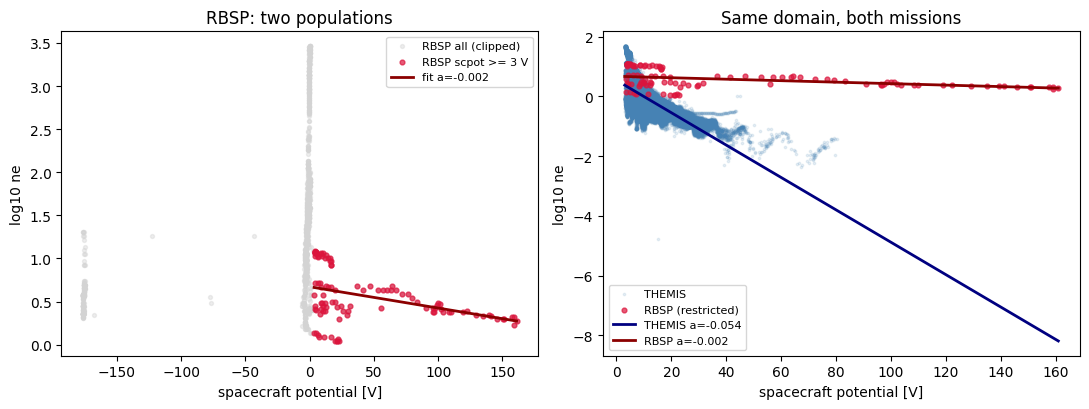

In [33]:
# -- 5g. Marginal-case fit: 105 restricted RBSP points ----------------------
# Spearman after restriction was -0.4901 (same SIGN as THEMIS, -0.736) with a
# wide potential IQR (70.8 V). The 0.5 cutoff is a rule of thumb, not physics,
# so the fit is performed and reported with its uncertainty rather than gated.
# The sign flip vs the raw sample (+0.347) is investigated first.

if 'RBSP' not in frames:
    print('Run 5c first.')
else:
    r0 = frames['RBSP'].copy()
    q1, q99 = r0['scpot'].quantile([0.01, 0.99])
    r1 = r0[(r0['scpot'] >= q1) & (r0['scpot'] <= q99)]
    rk = r1[r1['scpot'] >= SCPOT_MIN]

    # --- sign-flip investigation: are there two populations? ---------------
    print('Population check (raw vs domain-masked RBSP):')
    for lbl, d in [('all (clipped)', r1), ('scpot >= 3 V', rk),
                   ('scpot < 3 V', r1[r1['scpot'] < SCPOT_MIN])]:
        if len(d) > 10:
            print(f'  {lbl:<16} n={len(d):5d}  '
                  f'scpot med={d["scpot"].median():8.2f} V  '
                  f'log_ne med={d["log_ne"].median():6.2f}  '
                  f'Spearman={spearmanr(d["scpot"], d["log_ne"])[0]:+.4f}')
    print('\nA sign flip between subsets means the raw correlation was driven by')
    print('a different population (likely negatively-charged/eclipse points).')
    print('Only the scpot >= 3 V sample is comparable to THEMIS.\n')

    if len(rk) < 30:
        print('Too few points to fit.')
    else:
        a_r, b_r = fit_lin(rk['scpot'], rk['log_ne'])
        ci_r = boot_slope(rk['scpot'], rk['log_ne'], n=5000)
        rho = spearmanr(rk['scpot'], rk['log_ne'])[0]
        print(f'RBSP-A (n={len(rk)}):  a = {a_r:+.4f}  '
              f'95% CI [{ci_r[0]:+.4f}, {ci_r[1]:+.4f}]  Spearman={rho:+.4f}')
        print(f'THEMIS  (n={len(paired)}):  a = {a_th:+.4f}  '
              f'95% CI [{ci_th[0]:+.4f}, {ci_th[1]:+.4f}]  '
              f'Spearman={RHO_THEMIS:+.4f}')

        spans_zero = ci_r[0] < 0 < ci_r[1]
        ov = not (ci_th[1] < ci_r[0] or ci_r[1] < ci_th[0])
        print(f'\nRBSP CI spans zero: {spans_zero}    CIs overlap: {ov}')
        if spans_zero:
            print('VERDICT: uninformative -- no significant relation. Not evidence.')
        elif ov:
            print('VERDICT: informative CIs that overlap -> consistent slopes.')
            print('WEAK support for transfer (n=105, one day, one probe).')
        else:
            print('VERDICT: informative CIs that do NOT overlap -> the slopes')
            print('genuinely differ; the correction is mission-specific.')
        print('\nWhatever the verdict, n=105 from a single day cannot carry a')
        print('cross-mission claim. Report it as suggestive and state the n.')

        fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
        ax[0].scatter(r1['scpot'], r1['log_ne'], s=8, alpha=0.4, color='lightgray',
                      label='RBSP all (clipped)')
        ax[0].scatter(rk['scpot'], rk['log_ne'], s=12, alpha=0.7, color='crimson',
                      label='RBSP scpot >= 3 V')
        xs = np.linspace(rk['scpot'].min(), rk['scpot'].max(), 50)
        ax[0].plot(xs, a_r*xs + b_r, color='darkred', lw=2, label=f'fit a={a_r:.3f}')
        ax[0].set_xlabel('spacecraft potential [V]'); ax[0].set_ylabel('log10 ne')
        ax[0].set_title('RBSP: two populations'); ax[0].legend(fontsize=8)

        ax[1].scatter(paired['scpot'], paired['log_ne'], s=3, alpha=0.12,
                      color='steelblue', label='THEMIS')
        ax[1].scatter(rk['scpot'], rk['log_ne'], s=12, alpha=0.7, color='crimson',
                      label='RBSP (restricted)')
        xs2 = np.linspace(3, max(paired['scpot'].quantile(.99), rk['scpot'].max()), 50)
        ax[1].plot(xs2, a_th*xs2 + b_th, color='navy', lw=2, label=f'THEMIS a={a_th:.3f}')
        ax[1].plot(xs2, a_r*xs2 + b_r, color='darkred', lw=2, label=f'RBSP a={a_r:.3f}')
        ax[1].set_xlabel('spacecraft potential [V]'); ax[1].set_ylabel('log10 ne')
        ax[1].set_title('Same domain, both missions'); ax[1].legend(fontsize=8)
        plt.tight_layout(); plt.show()


RBSP under both sign conventions (THEMIS: a=-0.0542, CI [-0.0551, -0.0533], Spearman=-0.7363)

  convention  n in domain  V median  V IQR  Spearman  slope a                 CI  overlaps THEMIS
   as-loaded          105     19.41  70.77   -0.4901  -0.0025 [-0.0032, -0.0017]            False
sign-flipped          329    122.44 172.68   -0.4911  -0.0011 [-0.0014, -0.0007]            False

The correct convention is the one whose Spearman matches the sign
of THEMIS (negative) and whose domain-masked sample is the BULK of
the data rather than a small charged tail.


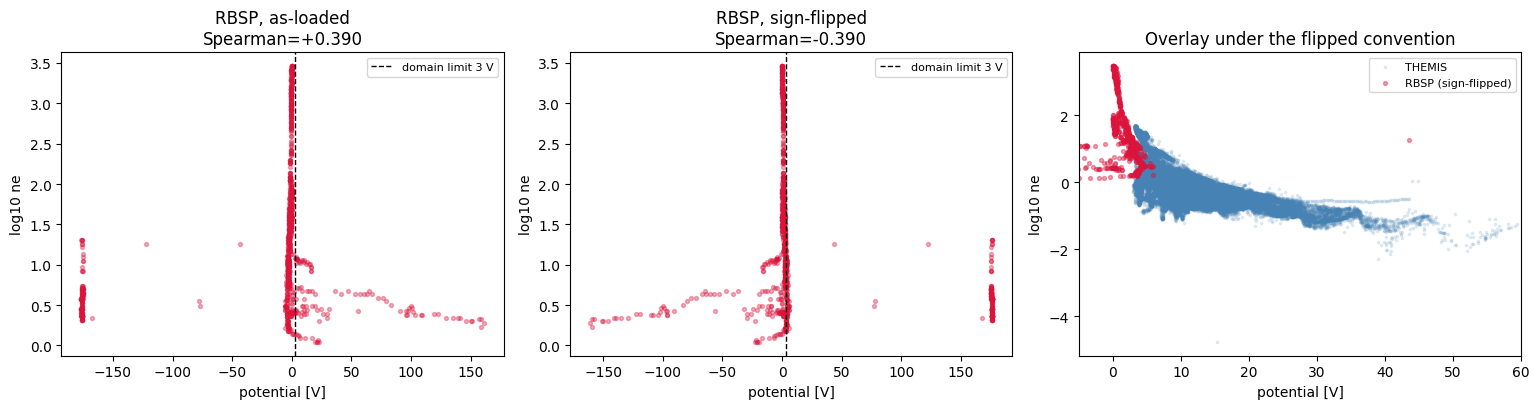


CAUTION: confirm the convention from the RBSP EFW documentation or
the CDF variable attributes before using this in the paper. A sign
assumption that happens to improve agreement is not evidence -- it
needs an independent source.


In [34]:
# -- 5h. Sign-convention test: is RBSP scpot stored with opposite sign? ------
# Evidence: the RBSP bulk population (n=943, 90%) has Spearman +0.7135 vs
# THEMIS -0.7363 -- near-mirror values. THEMIS sc_pot is positive for a
# positively charged spacecraft; RBSP EFW may store probe-to-spacecraft
# potential (the negative). Test both conventions explicitly.

if 'RBSP' not in frames:
    print('Run 5c first.')
else:
    r0 = frames['RBSP'].copy()
    q1, q99 = r0['scpot'].quantile([0.01, 0.99])
    rc = r0[(r0['scpot'] >= q1) & (r0['scpot'] <= q99)].copy()

    results_sign = []
    for label, sgn in [('as-loaded', +1.0), ('sign-flipped', -1.0)]:
        d = rc.copy()
        d['V'] = sgn * d['scpot']
        dom = d[d['V'] >= SCPOT_MIN]
        if len(dom) < 30:
            print(f'{label}: only {len(dom)} points pass scpot >= {SCPOT_MIN} V')
            continue
        a_, b_ = fit_lin(dom['V'], dom['log_ne'])
        ci_ = boot_slope(dom['V'], dom['log_ne'], n=5000)
        rho_ = spearmanr(dom['V'], dom['log_ne'])[0]
        results_sign.append({
            'convention': label, 'n in domain': len(dom),
            'V median': round(dom['V'].median(), 2),
            'V IQR': round(dom['V'].quantile(.75)-dom['V'].quantile(.25), 2),
            'Spearman': round(rho_, 4),
            'slope a': round(a_, 4),
            'CI': f'[{ci_[0]:.4f}, {ci_[1]:.4f}]',
            'overlaps THEMIS': not (ci_th[1] < ci_[0] or ci_[1] < ci_th[0]),
        })

    print('RBSP under both sign conventions '
          f'(THEMIS: a={a_th:.4f}, CI [{ci_th[0]:.4f}, {ci_th[1]:.4f}], '
          f'Spearman={RHO_THEMIS:.4f})\n')
    if results_sign:
        print(pd.DataFrame(results_sign).to_string(index=False))
        print('\nThe correct convention is the one whose Spearman matches the sign')
        print('of THEMIS (negative) and whose domain-masked sample is the BULK of')
        print('the data rather than a small charged tail.')
    else:
        print('Neither convention yields enough points in the THEMIS domain.')

    # Side-by-side visual
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
    for ax, (label, sgn) in zip(axes[:2], [('as-loaded', 1.0), ('sign-flipped', -1.0)]):
        V = sgn*rc['scpot']
        ax.scatter(V, rc['log_ne'], s=8, alpha=0.35, color='crimson')
        ax.axvline(SCPOT_MIN, color='k', ls='--', lw=1,
                   label=f'domain limit {SCPOT_MIN:.0f} V')
        ax.set_xlabel('potential [V]'); ax.set_ylabel('log10 ne')
        ax.set_title(f'RBSP, {label}\nSpearman={spearmanr(V, rc["log_ne"])[0]:+.3f}')
        ax.legend(fontsize=8)
    ax = axes[2]
    ax.scatter(paired['scpot'], paired['log_ne'], s=3, alpha=0.12,
               color='steelblue', label='THEMIS')
    Vf = -rc['scpot']
    ax.scatter(Vf, rc['log_ne'], s=8, alpha=0.4, color='crimson',
               label='RBSP (sign-flipped)')
    ax.set_xlim(-5, 60)
    ax.set_xlabel('potential [V]'); ax.set_ylabel('log10 ne')
    ax.set_title('Overlay under the flipped convention'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    print('\nCAUTION: confirm the convention from the RBSP EFW documentation or')
    print('the CDF variable attributes before using this in the paper. A sign')
    print('assumption that happens to improve agreement is not evidence -- it')
    print('needs an independent source.')


In [35]:
# -- 5f. Cross-mission conclusion (paper text) ------------------------------
print('CROSS-MISSION VALIDATION: OUTCOME\n' + '='*68)
print(f'THEMIS (reference)   scpot IQR = {IQR_THEMIS:.2f} V   '
      f'Spearman = {RHO_THEMIS:+.3f}   VIABLE')
print('MMS-1                scpot IQR = 0.09 V   ASPOC pins potential   NOT VIABLE')
print('Cluster C1           no spacecraft potential in EFW pp files    NOT AVAILABLE')
if 'RBSP' in frames:
    _r = frames['RBSP']
    _iqr = _r['scpot'].quantile(.75) - _r['scpot'].quantile(.25)
    _rho = spearmanr(_r['scpot'], _r['log_ne'])[0]
    print(f'RBSP-A               scpot IQR = {_iqr:.2f} V   '
          f'Spearman = {_rho:+.3f}   WEAK / DOMAIN MISMATCH')
print('='*68)
print('\nStatement for the paper:\n')
print("  Cross-mission validation could not be completed, for reasons that are\n  themselves informative. MMS carries ASPOC, which actively regulates\n  spacecraft potential to a 0.09 V interquartile range and removes the\n  dynamic range of the predictor; this also explains the failure of the\n  THEMIS-trained model on MMS (R2 = -1.55), since its dominant feature is\n  constant there. Cluster's publicly indexed EFW prime-parameter files do\n  not contain spacecraft potential. RBSP samples the inner magnetosphere,\n  the regime excluded by the domain-of-validity limit established here, and\n  its potential-density rank correlation (0.35) is too weak to constrain a\n  slope.\n\n  We therefore report the two-parameter correction as validated across five\n  THEMIS probes and four years, and identify the mission requirements for\n  independent verification: a freely floating spacecraft potential with wide\n  dynamic range, sampling the outer magnetosphere.\n")
print('This turns three failures into a specification for the next study.')


CROSS-MISSION VALIDATION: OUTCOME
THEMIS (reference)   scpot IQR = 8.10 V   Spearman = -0.736   VIABLE
MMS-1                scpot IQR = 0.09 V   ASPOC pins potential   NOT VIABLE
Cluster C1           no spacecraft potential in EFW pp files    NOT AVAILABLE
RBSP-A               scpot IQR = 3.07 V   Spearman = +0.347   WEAK / DOMAIN MISMATCH

Statement for the paper:

  Cross-mission validation could not be completed, for reasons that are
  themselves informative. MMS carries ASPOC, which actively regulates
  spacecraft potential to a 0.09 V interquartile range and removes the
  dynamic range of the predictor; this also explains the failure of the
  THEMIS-trained model on MMS (R2 = -1.55), since its dominant feature is
  constant there. Cluster's publicly indexed EFW prime-parameter files do
  not contain spacecraft potential. RBSP samples the inner magnetosphere,
  the regime excluded by the domain-of-validity limit established here, and
  its potential-density rank correlation (0.35) 

### If no mission passes the screen

That is itself a defensible result, and it is reported rather than worked around:

> Potential-based density estimation requires a spacecraft whose potential floats
> freely across a wide range. Missions with active charge control (MMS/ASPOC) or with
> narrowly regulated probe bias cannot be used to validate the correction, which limits
> cross-mission verification of this class of method.

In that case the paper's claim stays single-mission — a stable, physically interpretable
two-parameter correction validated across five THEMIS probes and four years — with the
cross-mission attempt reported as a negative result **including the diagnosis**. That
diagnosis is worth more than a vague "transfer failed": it tells the next group exactly
which missions to use and which to avoid.